
# Multimodal Identification of Informative Social Media Posts for Disaster Response

**COMP 1013 – Project 2.2: Implementation**

## Research Objective

This project investigates whether combining textual and visual information improves the classification of disaster-related social media posts as informative or not informative.

We compare four approaches:

1. Text-only classification using DistilBERT
2. Image-only classification using EfficientNet-B0
3. Early fusion of text and image features
4. Late fusion of text and image predictions

Performance will be evaluated using macro-F1, accuracy, precision, recall, AUROC and confusion matrices.


In [1]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Project folder exists:", Path.cwd().name == "CrisisMMD_Project")

for folder in ["text_features", "image_features", "results"]:
    path = Path.cwd() / folder
    print(f"{folder}: {'FOUND' if path.exists() else 'MISSING'}")

Current directory: C:\Users\georg\CrisisMMD_Project
Project folder exists: True
text_features: FOUND
image_features: FOUND
results: FOUND


In [3]:

# Reinstall required libraries
%pip install -q datasets transformers accelerate timm scikit-learn seaborn huggingface_hub

# Import libraries
import torch
import timm
import pandas as pd
import numpy as np

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel
from torchvision import transforms
from huggingface_hub import hf_hub_download
from PIL import Image
from tqdm.auto import tqdm

# Check GPU
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Environment restored successfully!")


Note: you may need to restart the kernel to use updated packages.
Device: cuda
GPU available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Environment restored successfully!


In [4]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Check runtime settings.")


PyTorch version: 2.14.1+cu126
GPU available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [5]:

from datasets import load_dataset

# Load the informativeness classification dataset
dataset = load_dataset("QCRI/CrisisMMD", "informative")

# Display dataset structure
print(dataset)


Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


DatasetDict({
    train: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 13608
    })
    dev: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 2237
    })
    test: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 2237
    })
})


## Dataset Exploration

This section examines the CrisisMMD dataset, including its structure,
class distribution, missing values and sample records. The analysis
provides an initial understanding of the data before preprocessing
and feature extraction.

In [6]:

import pandas as pd

# Convert the training dataset to a DataFrame
train_df = dataset["train"].to_pandas()

# Display dataset information
print("Dataset shape:", train_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nClass distribution:")
print(train_df["label"].value_counts())

print("\nFirst 5 records:")
display(train_df[
    ["tweet_text", "label", "event_name"]
].head())


Dataset shape: (13608, 7)

Column names:
['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label']

Class distribution:
label
0    8341
1    5267
Name: count, dtype: int64

First 5 records:


,tweet_text,label,event_name
0,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,0,california_wildfires
1,RT @Cal_OES: PLS SHARE: Weâ€™re capturing wild...,1,california_wildfires
2,RT @KAKEnews: California wildfires destroy mor...,0,california_wildfires
3,RT @KAKEnews: California wildfires destroy mor...,0,california_wildfires
4,RT @KAKEnews: California wildfires destroy mor...,0,california_wildfires


In [7]:

# Check missing values without decoding all images
metadata_cols = [
    "event_name", "tweet_id", "image_id",
    "tweet_text", "image_path", "label"
]

print("Missing values:")
print(train_df[metadata_cols].isnull().sum())

print("\nExact duplicate metadata rows:")
print(train_df[metadata_cols].duplicated().sum())

print("\nDuplicate tweet texts:")
print(train_df["tweet_text"].duplicated().sum())

print("\nLabel definitions:")
print(dataset["train"].features["label"])

print("\nDisaster event distribution:")
print(train_df["event_name"].value_counts())


Missing values:
event_name    0
tweet_id      0
image_id      0
tweet_text    0
image_path    0
label         0
dtype: int64

Exact duplicate metadata rows:
0

Duplicate tweet texts:
2024

Label definitions:
ClassLabel(names=['informative', 'not_informative'])

Disaster event distribution:
event_name
hurricane_maria         3462
hurricane_irma          3421
hurricane_harvey        3285
california_wildfires    1139
mexico_earthquake       1044
srilanka_floods          805
iraq_iran_earthquake     452
Name: count, dtype: int64


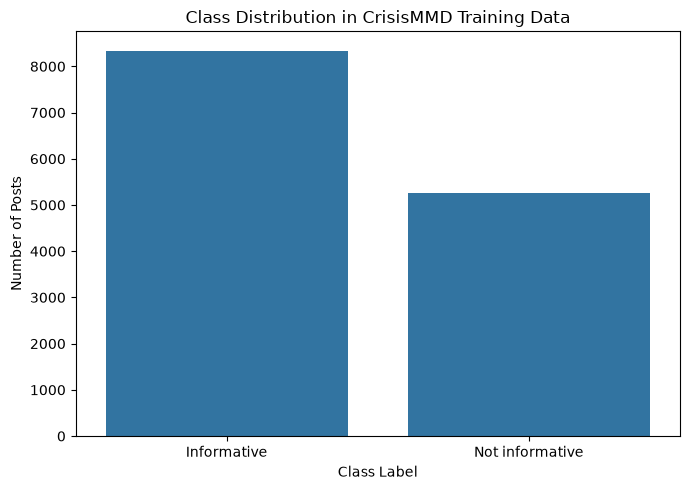

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

# Map numerical labels to class names
train_df["label_name"] = train_df["label"].map({
    0: "Informative",
    1: "Not informative"
})

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="label_name",
    order=["Informative", "Not informative"]
)

plt.title("Class Distribution in CrisisMMD Training Data")
plt.xlabel("Class Label")
plt.ylabel("Number of Posts")

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300)
plt.show()


In [9]:

from transformers import AutoTokenizer

# Load pretrained DistilBERT tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

# Select a sample tweet
sample_text = dataset["train"][0]["tweet_text"]

# Tokenize the text
encoded = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Original text:")
print(sample_text)

print("\nInput IDs shape:")
print(encoded["input_ids"].shape)

print("\nAttention mask shape:")
print(encoded["attention_mask"].shape)

print("\nDecoded tokens:")
print(tokenizer.convert_ids_to_tokens(
    encoded["input_ids"][0][:20]
))


Original text:
RT @Cal_OES: PLS SHARE: Weâ€™re capturing wildfire response, recovery info here: https://t.co/r89LKpjLPj https://t.co/HiA1oQF2Ax

Input IDs shape:
torch.Size([1, 128])

Attention mask shape:
torch.Size([1, 128])

Decoded tokens:
['[CLS]', 'rt', '@', 'cal', '_', 'o', '##es', ':', 'pl', '##s', 'share', ':', 'we', '##a', '##€', '##™', '##re', 'capturing', 'wild', '##fire']


In [10]:

# Check image availability and storage

print("Image feature:")
print(dataset["train"].features["image"])

print("\nFirst record image:")
print(dataset["train"][0]["image"])

print("\nFirst record image path:")
print(dataset["train"][0]["image_path"])

print("\nChecking first 10 records:")
for i in range(10):
    record = dataset["train"][i]
    print(
        i,
        "Image:", type(record["image"]).__name__,
        "Path:", record["image_path"]
    )


Image feature:
Image(mode=None, decode=True)

First record image:
None

First record image path:
data_image/california_wildfires/10_10_2017/917791291823591425_0.jpg

Checking first 10 records:
0 Image: NoneType Path: data_image/california_wildfires/10_10_2017/917791291823591425_0.jpg
1 Image: NoneType Path: data_image/california_wildfires/10_10_2017/917791291823591425_1.jpg
2 Image: NoneType Path: data_image/california_wildfires/10_10_2017/917793137925459968_0.jpg
3 Image: NoneType Path: data_image/california_wildfires/10_10_2017/917793137925459968_1.jpg
4 Image: NoneType Path: data_image/california_wildfires/10_10_2017/917793137925459968_2.jpg
5 Image: NoneType Path: data_image/california_wildfires/10_10_2017/917815040962695168_0.jpg
6 Image: NoneType Path: data_image/california_wildfires/10_10_2017/917815040962695168_1.jpg
7 Image: NoneType Path: data_image/california_wildfires/10_10_2017/917815040962695168_2.jpg
8 Image: NoneType Path: data_image/california_wildfires/10_10_2017/9178

In [11]:

import os

# Get the image path from the first record
image_path = dataset["train"][0]["image_path"]

print("Image path:", image_path)

# Check whether the image exists locally
print("Image exists:", os.path.exists(image_path))

# Check current working directory
print("Current directory:", os.getcwd())

# Show available files
print("\nFiles in current directory:")
print(os.listdir(".")[:20])


Image path: data_image/california_wildfires/10_10_2017/917791291823591425_0.jpg
Image exists: False
Current directory: C:\Users\georg\CrisisMMD_Project

Files in current directory:
['.ipynb_checkpoints', 'class_distribution.png', 'crisismmd_features.npz', 'CrisisMMD_Final(5)_(2)_(3).ipynb', 'image_features', 'results', 'text_features']


In [12]:

from huggingface_hub import list_repo_files

repo_files = list_repo_files(
    repo_id="QCRI/CrisisMMD",
    repo_type="dataset"
)

print("Files in the dataset repository:")

for filename in repo_files:
    print(filename)


Files in the dataset repository:
.gitattributes
README.md
damage/dev.json
damage/test.json
damage/train.json
data_image/california_wildfires/10_10_2017/917791044158185473_0.jpg
data_image/california_wildfires/10_10_2017/917791130590183424_0.jpg
data_image/california_wildfires/10_10_2017/917791291823591425_0.jpg
data_image/california_wildfires/10_10_2017/917791291823591425_1.jpg
data_image/california_wildfires/10_10_2017/917792092100988929_0.jpg
data_image/california_wildfires/10_10_2017/917792147700465664_0.jpg
data_image/california_wildfires/10_10_2017/917792930315821057_0.jpg
data_image/california_wildfires/10_10_2017/917793137925459968_0.jpg
data_image/california_wildfires/10_10_2017/917793137925459968_1.jpg
data_image/california_wildfires/10_10_2017/917793137925459968_2.jpg
data_image/california_wildfires/10_10_2017/917793158251077632_0.jpg
data_image/california_wildfires/10_10_2017/917793736918216706_0.jpg
data_image/california_wildfires/10_10_2017/917793881533571073_0.jpg
data_im

Looking for: data_image/california_wildfires/10_10_2017/917791291823591425_0.jpg


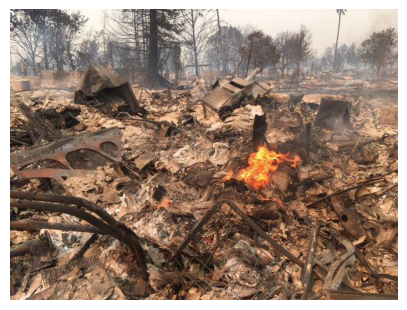

Image loaded successfully!


In [13]:

from huggingface_hub import hf_hub_download
from PIL import Image
import matplotlib.pyplot as plt

image_path = dataset["train"][0]["image_path"]

print("Looking for:", image_path)

try:
    local_path = hf_hub_download(
        repo_id="QCRI/CrisisMMD",
        repo_type="dataset",
        filename=image_path
    )

    sample_image = Image.open(local_path).convert("RGB")

    plt.figure(figsize=(5, 5))
    plt.imshow(sample_image)
    plt.axis("off")
    plt.show()

    print("Image loaded successfully!")

except Exception as e:
    print("Image loading failed:", e)


In [14]:

from transformers import AutoModel
import torch

# Load pretrained DistilBERT model
text_model = AutoModel.from_pretrained(
    "distilbert-base-uncased"
)

text_model = text_model.to(device)
text_model.eval()

# Select the same training record
sample_text = dataset["train"][0]["tweet_text"]

# Tokenize the text
inputs = tokenizer(
    sample_text,
    return_tensors="pt",
    padding="max_length",
    truncation=True,
    max_length=128
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Extract text features
with torch.no_grad():
    outputs = text_model(**inputs)

    # Use the [CLS] token representation
    text_features = outputs.last_hidden_state[:, 0, :]

print("Text feature shape:", text_features.shape)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Text feature shape: torch.Size([1, 768])


## Preliminary Pilot Experiment

The following experiment was used for initial feasibility
testing. The final model evaluation uses the complete
CrisisMMD training, development and test splits.

This section prepares a pilot subset of the CrisisMMD dataset
for multimodal classification.

The pilot dataset contains 200 training samples and 50
validation samples. The data includes text, image paths,
and binary informativeness labels.

The class distributions are examined to understand the
balance between informative and non-informative posts.

In [15]:

import numpy as np
import pandas as pd

SEED = 42

# Select reproducible pilot samples
pilot_train = dataset["train"].shuffle(
    seed=SEED
).select(range(200))

pilot_val = dataset["dev"].shuffle(
    seed=SEED
).select(range(50))

print("Pilot training records:", len(pilot_train))
print("Pilot validation records:", len(pilot_val))

print("\nTraining class distribution:")
print(pd.Series(pilot_train["label"]).value_counts())

print("\nValidation class distribution:")
print(pd.Series(pilot_val["label"]).value_counts())

print("\nSample image path:")
print(pilot_train[0]["image_path"])


Pilot training records: 200
Pilot validation records: 50

Training class distribution:
0    125
1     75
Name: count, dtype: int64

Validation class distribution:
0    35
1    15
Name: count, dtype: int64

Sample image path:
data_image/hurricane_irma/19_9_2017/909965919949955072_0.jpg


In [16]:

from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
import os

# Download images for one dataset split
def download_images(data):
    downloaded = {}
    failed = {}

    # Avoid downloading repeated image paths
    paths = list(dict.fromkeys(data["image_path"]))

    for path in tqdm(paths, desc="Downloading images"):
        try:
            local_path = hf_hub_download(
                repo_id="QCRI/CrisisMMD",
                repo_type="dataset",
                filename=path
            )
            downloaded[path] = local_path

        except Exception as e:
            failed[path] = str(e)

    return downloaded, failed

# Download training images
train_images, train_failed = download_images(pilot_train)

# Download validation images
val_images, val_failed = download_images(pilot_val)

print("\nTraining images downloaded:", len(train_images))
print("Validation images downloaded:", len(val_images))
print("Training failures:", len(train_failed))
print("Validation failures:", len(val_failed))



Training images downloaded: 200
Validation images downloaded: 50
Training failures: 0
Validation failures: 0


## Feature Extraction

This section extracts numerical representations from
the text and image modalities using pretrained deep
learning models.

### Text Feature Extraction
DistilBERT is used to extract 768-dimensional
feature vectors from social media text.

### Image Feature Extraction
EfficientNet-B0 is used to extract 1280-dimensional
feature vectors from disaster-related images.

These representations are subsequently used for
unimodal classification and multimodal fusion.

In [17]:

import torch
import timm

from transformers import AutoTokenizer, AutoModel
from torchvision import transforms

# Select GPU
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load DistilBERT tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

# Load DistilBERT model
text_model = AutoModel.from_pretrained(
    "distilbert-base-uncased"
).to(device)

text_model.eval()

print("DistilBERT loaded successfully!")

# Load EfficientNet-B0 feature extractor
image_model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=0
).to(device)

image_model.eval()

# Image preprocessing
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("EfficientNet-B0 loaded successfully!")
print("Device:", device)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT loaded successfully!
EfficientNet-B0 loaded successfully!
Device: cuda


In [18]:

# Preprocess the successfully loaded image
image_tensor = image_transform(sample_image)

print("Processed image shape:", image_tensor.shape)

# Extract image features using EfficientNet-B0
image_model.eval()

with torch.no_grad():
    image_features = image_model(
        image_tensor.unsqueeze(0).to(device)
    )

print("Extracted feature shape:", image_features.shape)


Processed image shape: torch.Size([3, 224, 224])
Extracted feature shape: torch.Size([1, 1280])


In [19]:

import torch

# Combine text and image features
combined_features = torch.cat(
    [text_features, image_features],
    dim=1
)

print("Text features:", text_features.shape)
print("Image features:", image_features.shape)
print("Combined features:", combined_features.shape)

# Verify the combined feature dimensions
assert combined_features.shape == (1, 2048)

print("\nEarly fusion successful!")


Text features: torch.Size([1, 768])
Image features: torch.Size([1, 1280])
Combined features: torch.Size([1, 2048])

Early fusion successful!


In [20]:

from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm

def restore_images(data):
    restored = {}
    failed = {}
    cached_count = 0
    downloaded_count = 0

    paths = list(dict.fromkeys(data["image_path"]))

    for path in tqdm(paths, desc="Restoring images"):
        try:
            # Try existing local cache first
            try:
                local_path = hf_hub_download(
                    repo_id="QCRI/CrisisMMD",
                    repo_type="dataset",
                    filename=path,
                    local_files_only=True
                )
                cached_count += 1

            except Exception:
                # Download only if not cached
                local_path = hf_hub_download(
                    repo_id="QCRI/CrisisMMD",
                    repo_type="dataset",
                    filename=path
                )
                downloaded_count += 1

            restored[path] = local_path

        except Exception as e:
            failed[path] = str(e)

    print("Cached images:", cached_count)
    print("New downloads:", downloaded_count)
    print("Failed images:", len(failed))

    return restored, failed

# Restore training images
print("TRAINING IMAGES")
train_images, train_failed = restore_images(pilot_train)

# Restore validation images
print("\nVALIDATION IMAGES")
val_images, val_failed = restore_images(pilot_val)

print("\nTotal training images:", len(train_images))
print("Total validation images:", len(val_images))


TRAINING IMAGES


Restoring images:   0%|          | 0/200 [00:00<?, ?it/s]

Cached images: 200
New downloads: 0
Failed images: 0

VALIDATION IMAGES


Restoring images:   0%|          | 0/50 [00:00<?, ?it/s]

Cached images: 50
New downloads: 0
Failed images: 0

Total training images: 200
Total validation images: 50


In [21]:

import torch
import numpy as np
from tqdm.auto import tqdm

# Extract DistilBERT features in batches
def extract_text_features(data, batch_size=16):
    all_features = []

    text_model.eval()

    for start in tqdm(
        range(0, len(data), batch_size),
        desc="Extracting text features"
    ):
        end = min(start + batch_size, len(data))

        texts = data[start:end]["tweet_text"]

        # Tokenize a batch of tweets
        inputs = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        # Extract pretrained features
        with torch.no_grad():
            outputs = text_model(**inputs)
            features = outputs.last_hidden_state[:, 0, :]

        all_features.append(features.cpu().numpy())

    return np.concatenate(all_features, axis=0)

# Training text features
X_train_text = extract_text_features(pilot_train)

# Validation text features
X_val_text = extract_text_features(pilot_val)

print("\nTraining text features:", X_train_text.shape)
print("Validation text features:", X_val_text.shape)


Extracting text features:   0%|          | 0/13 [00:00<?, ?it/s]

Extracting text features:   0%|          | 0/4 [00:00<?, ?it/s]


Training text features: (200, 768)
Validation text features: (50, 768)


In [22]:

import torch
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

# Extract EfficientNet-B0 image features
def extract_image_features(data, image_paths, batch_size=16):
    all_features = []
    image_model.eval()

    for start in tqdm(
        range(0, len(data), batch_size),
        desc="Extracting image features"
    ):
        end = min(start + batch_size, len(data))
        batch_images = []

        for i in range(start, end):
            path = data[i]["image_path"]
            local_path = image_paths[path]

            # Load and preprocess image
            with Image.open(local_path) as img:
                image = img.convert("RGB")
                image_tensor = image_transform(image)

            batch_images.append(image_tensor)

        # Combine images into one batch
        batch_tensor = torch.stack(batch_images).to(device)

        # Extract pretrained image features
        with torch.no_grad():
            features = image_model(batch_tensor)

        all_features.append(features.cpu().numpy())

    return np.concatenate(all_features, axis=0)


# Extract training image features
X_train_image = extract_image_features(
    pilot_train,
    train_images
)

# Extract validation image features
X_val_image = extract_image_features(
    pilot_val,
    val_images
)

print("\nTraining image features:", X_train_image.shape)
print("Validation image features:", X_val_image.shape)


Extracting image features:   0%|          | 0/13 [00:00<?, ?it/s]

Extracting image features:   0%|          | 0/4 [00:00<?, ?it/s]


Training image features: (200, 1280)
Validation image features: (50, 1280)


In [23]:
import numpy as np

np.savez_compressed(
    "crisismmd_features.npz",
    X_train_text=X_train_text,
    X_val_text=X_val_text,
    X_train_image=X_train_image,
    X_val_image=X_val_image,
    y_train=np.array(pilot_train["label"]),
    y_val=np.array(pilot_val["label"])
)

print("Features saved successfully!")

Features saved successfully!


In [24]:
import os

filename = os.path.abspath("crisismmd_features.npz")

print("Saved file:", filename)
print("File exists:", os.path.exists(filename))
print("File size (MB):", round(os.path.getsize(filename) / 1024**2, 2))

Saved file: C:\Users\georg\CrisisMMD_Project\crisismmd_features.npz
File exists: True
File size (MB): 1.81


In [25]:
import numpy as np

data = np.load("crisismmd_features.npz")

for key in data.files:
    print(key, data[key].shape)

X_train_text (200, 768)
X_val_text (50, 768)
X_train_image (200, 1280)
X_val_image (50, 1280)
y_train (200,)
y_val (50,)


In [26]:
X_train_text = data["X_train_text"]
X_val_text = data["X_val_text"]
X_train_image = data["X_train_image"]
X_val_image = data["X_val_image"]

print("Training text:", X_train_text.shape)
print("Validation text:", X_val_text.shape)
print("Training image:", X_train_image.shape)
print("Validation image:", X_val_image.shape)

Training text: (200, 768)
Validation text: (50, 768)
Training image: (200, 1280)
Validation image: (50, 1280)



## Model Training and Multimodal Fusion

This section implements four classification approaches to identify informative and non-informative disaster-related social media posts.

### 1. Text-only Classification
A logistic regression classifier is trained using 768-dimensional DistilBERT text features.


In [27]:
import numpy as np
import os

print("Current folder:", os.getcwd())
print("Feature file exists:", os.path.exists("crisismmd_features.npz"))

if os.path.exists("crisismmd_features.npz"):
    data = np.load("crisismmd_features.npz")
    print("Features loaded successfully!")
    print(data.files)

Current folder: C:\Users\georg\CrisisMMD_Project
Feature file exists: True
Features loaded successfully!
['X_train_text', 'X_val_text', 'X_train_image', 'X_val_image', 'y_train', 'y_val']


In [28]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load saved features
X_train_text = data["X_train_text"]
X_val_text = data["X_val_text"]
y_train = data["y_train"]
y_val = data["y_val"]

# Create text-only classifier
text_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

# Train classifier
text_classifier.fit(X_train_text, y_train)

# Predict validation labels
y_pred_text = text_classifier.predict(X_val_text)

# Evaluate performance
print("Text-only Baseline Results")
print("--------------------------")
print("Accuracy:", accuracy_score(y_val, y_pred_text))
print("Macro F1:", f1_score(
    y_val, y_pred_text, average="macro"
))

print("\nClassification Report:")
print(classification_report(
    y_val, y_pred_text,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_text))


Text-only Baseline Results
--------------------------
Accuracy: 0.66
Macro F1: 0.6263736263736264

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.69      0.74        35
           1       0.45      0.60      0.51        15

    accuracy                           0.66        50
   macro avg       0.62      0.64      0.63        50
weighted avg       0.69      0.66      0.67        50


Confusion Matrix:
[[24 11]
 [ 6  9]]


### 2. Image-only Classification
A logistic regression classifier is trained using 1,280-dimensional EfficientNet-B0 image features.

In [29]:

# Load image features
X_train_image = data["X_train_image"]
X_val_image = data["X_val_image"]

# Create image-only classifier
image_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

# Train image classifier
image_classifier.fit(X_train_image, y_train)

# Predict validation labels
y_pred_image = image_classifier.predict(X_val_image)

# Evaluate image-only model
print("Image-only Baseline Results")
print("---------------------------")

print("Accuracy:", accuracy_score(y_val, y_pred_image))
print("Macro F1:", f1_score(
    y_val, y_pred_image, average="macro"
))

print("\nClassification Report:")
print(classification_report(
    y_val, y_pred_image,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_image))


Image-only Baseline Results
---------------------------
Accuracy: 0.62
Macro F1: 0.49333333333333335

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.80      0.75        35
           1       0.30      0.20      0.24        15

    accuracy                           0.62        50
   macro avg       0.50      0.50      0.49        50
weighted avg       0.58      0.62      0.59        50


Confusion Matrix:
[[28  7]
 [12  3]]



### 3. Early Fusion
Text and image feature vectors are concatenated into a 2,048-dimensional representation before classification.

In [30]:

import numpy as np

# Combine text and image features
X_train_fusion = np.concatenate(
    [X_train_text, X_train_image],
    axis=1
)

X_val_fusion = np.concatenate(
    [X_val_text, X_val_image],
    axis=1
)

print("Training fusion shape:", X_train_fusion.shape)
print("Validation fusion shape:", X_val_fusion.shape)

# Create early-fusion classifier
fusion_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

# Train model
fusion_classifier.fit(X_train_fusion, y_train)

# Predict validation labels
y_pred_fusion = fusion_classifier.predict(X_val_fusion)

# Evaluate
print("\nEarly Fusion Results")
print("--------------------")
print("Accuracy:", accuracy_score(y_val, y_pred_fusion))
print("Macro F1:", f1_score(
    y_val, y_pred_fusion, average="macro"
))

print("\nClassification Report:")
print(classification_report(
    y_val, y_pred_fusion,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_fusion))


Training fusion shape: (200, 2048)
Validation fusion shape: (50, 2048)

Early Fusion Results
--------------------
Accuracy: 0.68
Macro F1: 0.5841995841995842

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.83      0.78        35
           1       0.45      0.33      0.38        15

    accuracy                           0.68        50
   macro avg       0.60      0.58      0.58        50
weighted avg       0.66      0.68      0.66        50


Confusion Matrix:
[[29  6]
 [10  5]]


### 4. Late Fusion
Prediction probabilities from the independently trained text-only and image-only classifiers are combined using equal-weight averaging.

All classifiers use standardised features and are evaluated on the same validation samples to ensure a consistent comparison.

In [31]:

import numpy as np

# Obtain probabilities for Class 1
text_probs = text_classifier.predict_proba(
    X_val_text
)[:, 1]

image_probs = image_classifier.predict_proba(
    X_val_image
)[:, 1]

# Late fusion: average prediction probabilities
late_fusion_probs = (
    0.5 * text_probs +
    0.5 * image_probs
)

# Convert probabilities to predictions
y_pred_late = (late_fusion_probs >= 0.5).astype(int)

# Evaluate late fusion
print("Late Fusion Results")
print("-------------------")

print("Accuracy:", accuracy_score(y_val, y_pred_late))
print("Macro F1:", f1_score(
    y_val, y_pred_late, average="macro"
))

print("\nClassification Report:")
print(classification_report(
    y_val, y_pred_late,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_late))


Late Fusion Results
-------------------
Accuracy: 0.68
Macro F1: 0.6190476190476191

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.77      0.77        35
           1       0.47      0.47      0.47        15

    accuracy                           0.68        50
   macro avg       0.62      0.62      0.62        50
weighted avg       0.68      0.68      0.68        50


Confusion Matrix:
[[27  8]
 [ 8  7]]



## Model Evaluation and Comparison

This section evaluates the performance of four classification approaches: text-only, image-only, early fusion, and late fusion.

Model performance is compared using accuracy, macro-averaged F1-score, confusion matrices, and ROC-AUC.

Macro-F1 is particularly important because it gives equal importance to both classes, helping assess performance when the class distribution is imbalanced.

Confusion matrices are used to examine classification errors, while ROC curves and AUC scores evaluate the models' ability to distinguish informative from non-informative posts.

The results provide evidence for assessing whether multimodal fusion improves classification performance compared with unimodal approaches.


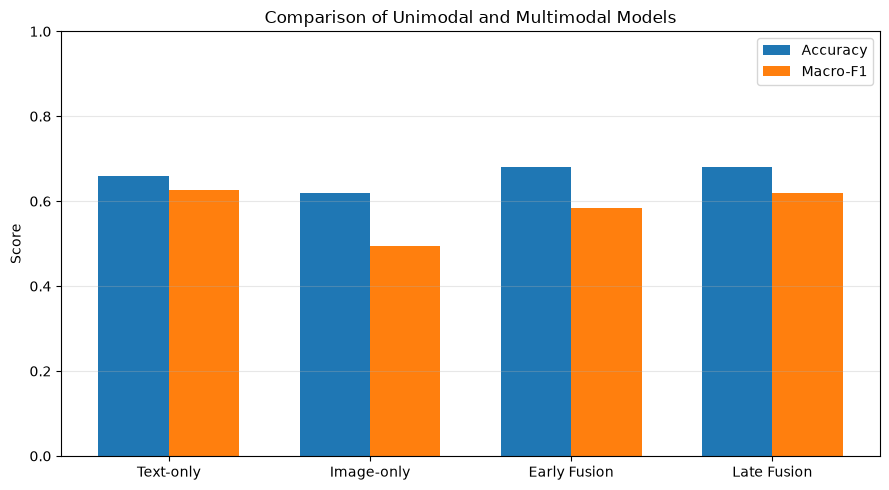

,Model,Accuracy,Macro-F1
0,Text-only,0.66,0.6264
1,Image-only,0.62,0.4933
2,Early Fusion,0.68,0.5842
3,Late Fusion,0.68,0.6190


In [32]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results_df = pd.DataFrame({
    "Model": [
        "Text-only",
        "Image-only",
        "Early Fusion",
        "Late Fusion"
    ],
    "Accuracy": [0.66, 0.62, 0.68, 0.68],
    "Macro-F1": [0.6264, 0.4933, 0.5842, 0.6190]
})

x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, results_df["Accuracy"],
        width, label="Accuracy")

plt.bar(x + width/2, results_df["Macro-F1"],
        width, label="Macro-F1")

plt.xticks(x, results_df["Model"])
plt.ylabel("Score")
plt.title("Comparison of Unimodal and Multimodal Models")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(results_df)


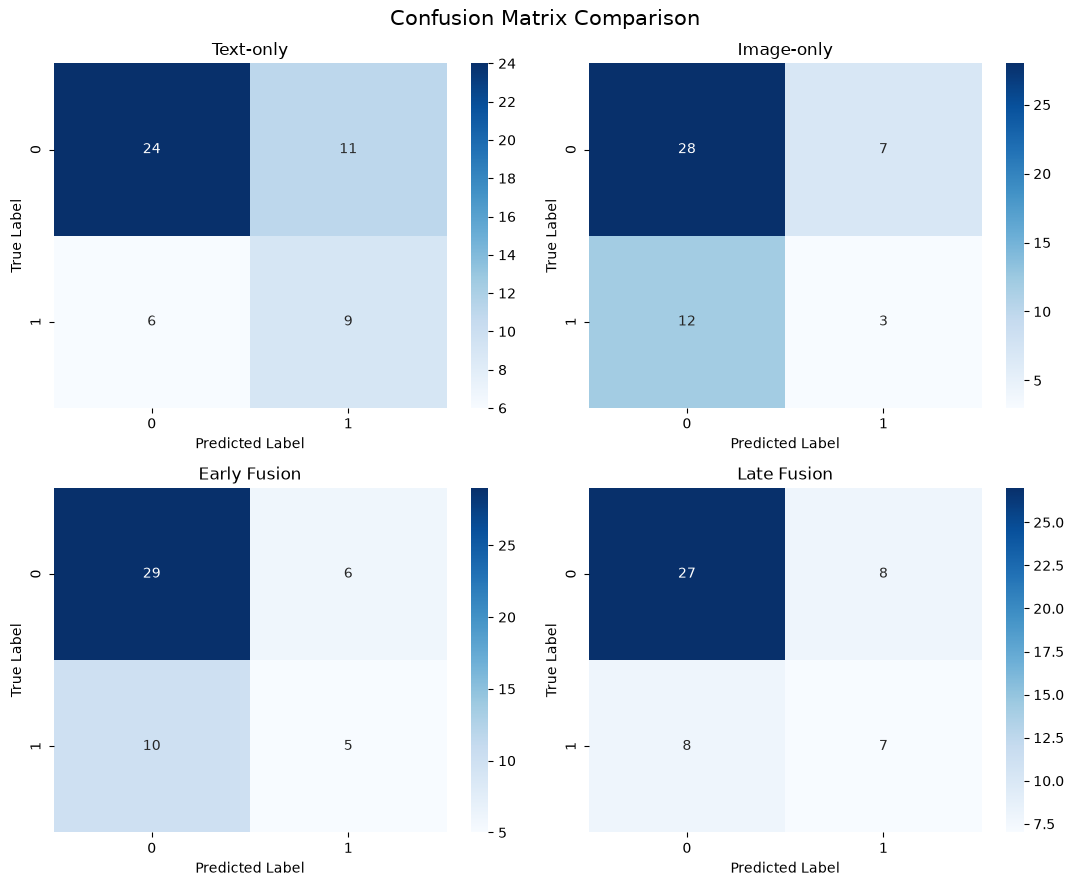

In [33]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models = {
    "Text-only": y_pred_text,
    "Image-only": y_pred_image,
    "Early Fusion": y_pred_fusion,
    "Late Fusion": y_pred_late
}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, predictions) in zip(axes.flat, models.items()):
    cm = confusion_matrix(y_val, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[0, 1],
        yticklabels=[0, 1],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.suptitle("Confusion Matrix Comparison", fontsize=15)
plt.tight_layout()
plt.show()


In [34]:
from sklearn.metrics import accuracy_score, f1_score

train_predictions = text_classifier.predict(X_train_text)
val_predictions = text_classifier.predict(X_val_text)

print("Text-only model: Overfitting Assessment")
print("Training accuracy:", accuracy_score(y_train, train_predictions))
print("Validation accuracy:", accuracy_score(y_val, val_predictions))
print("Training macro-F1:", f1_score(y_train, train_predictions, average="macro"))
print("Validation macro-F1:", f1_score(y_val, val_predictions, average="macro"))

Text-only model: Overfitting Assessment
Training accuracy: 1.0
Validation accuracy: 0.66
Training macro-F1: 1.0
Validation macro-F1: 0.6263736263736264


### Results and Discussion

Four classification approaches were evaluated on a pilot validation set of 50 CrisisMMD samples: text-only, image-only, early fusion and late fusion.

The text-only model achieved 66% accuracy and a macro-F1 score of 0.6264, outperforming the image-only model, which achieved 62% accuracy and 0.4933 macro-F1.

Both early and late fusion achieved the highest accuracy of 68%. However, late fusion achieved a higher macro-F1 score (0.6190) than early fusion (0.5842), indicating more balanced performance across the two classes.

The confusion matrices revealed differences in the models' ability to identify Class 1. The text-only model correctly identified 9 of 15 Class 1 samples, compared with 3 for image-only, 5 for early fusion and 7 for late fusion.

Although multimodal fusion slightly improved overall accuracy compared with text-only classification, it did not improve macro-F1. This suggests that combining image and text representations does not automatically improve classification performance.

These findings are preliminary because the pilot experiment used only 200 training samples and 50 validation samples. The small sample size and class imbalance may affect the reliability and generalisability of the results. Further experiments using larger datasets, hyperparameter tuning and repeated evaluation are needed before drawing stronger conclusions.

The ROC-AUC analysis further demonstrated differences in model discrimination. Early fusion achieved the highest ROC-AUC (0.7124), followed by text-only (0.6876), late fusion (0.6590), and image-only (0.5848). Although early fusion demonstrated the strongest discrimination across classification thresholds, the text-only model achieved the highest macro-F1 at the selected classification threshold. This highlights the importance of evaluating multiple performance metrics rather than relying solely on accuracy.

In [35]:

from sklearn.metrics import roc_auc_score

model_probabilities = {
    "Text-only": text_classifier.predict_proba(X_val_text)[:, 1],
    "Image-only": image_classifier.predict_proba(X_val_image)[:, 1],
    "Early Fusion": fusion_classifier.predict_proba(X_val_fusion)[:, 1],
    "Late Fusion": late_fusion_probs
}

for name, probs in model_probabilities.items():
    auc = roc_auc_score(y_val, probs)
    print(f"{name}: AUROC = {auc:.4f}")


Text-only: AUROC = 0.6876
Image-only: AUROC = 0.5867
Early Fusion: AUROC = 0.7124
Late Fusion: AUROC = 0.6610


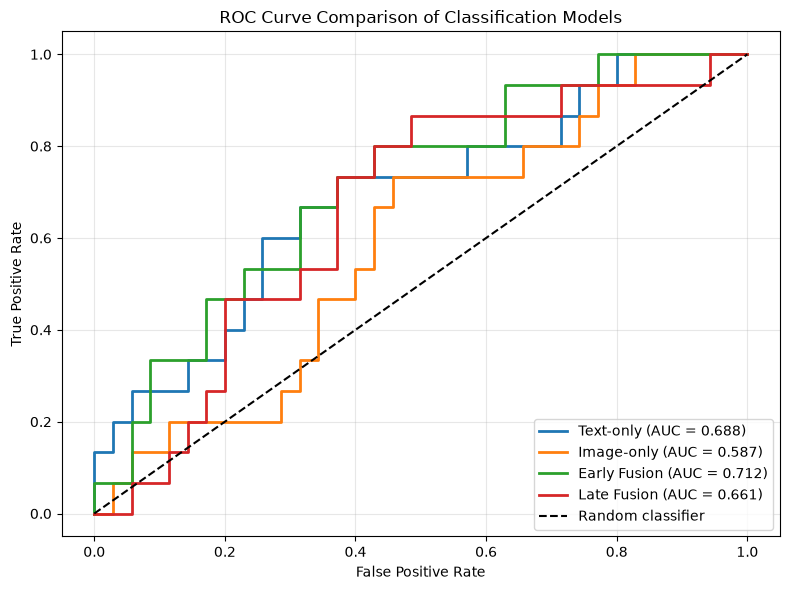

In [36]:

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, probs in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_val, probs)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--",
         label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Classification Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### ROC-AUC Analysis

Receiver Operating Characteristic (ROC) curves were used to evaluate the discriminative ability of the four classification models across different decision thresholds.

Early fusion achieved the highest AUROC of 0.7124, followed by text-only (0.6876), late fusion (0.6590) and image-only (0.5848).

Although early fusion achieved the highest AUROC, text-only classification produced the highest macro-F1 score (0.6264). This difference indicates that the model with the strongest ranking performance does not necessarily achieve the best classification balance at the default decision threshold.

The ROC curves also demonstrate that all four models achieved AUROC values above 0.5, suggesting some ability to distinguish between informative and non-informative posts.

However, these results should be interpreted cautiously because the pilot validation set contained only 50 samples, including 15 Class 1 examples. A larger evaluation set is required to establish whether the observed differences are reliable.

In [37]:
import numpy as np
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()

data = np.load(PROJECT_DIR / "crisismmd_features.npz")
X_train_text = data["X_train_text"]
X_val_text = data["X_val_text"]

X_train_image = data["X_train_image"]
X_val_image = data["X_val_image"]

y_train = data["y_train"]
y_val = data["y_val"]

print("Training text:", X_train_text.shape)
print("Validation text:", X_val_text.shape)
print("Training image:", X_train_image.shape)
print("Validation image:", X_val_image.shape)

print("Features restored successfully!")

Training text: (200, 768)
Validation text: (50, 768)
Training image: (200, 1280)
Validation image: (50, 1280)
Features restored successfully!


In [38]:
import numpy as np

data = np.load(PROJECT_DIR / "crisismmd_features.npz")

print("Available arrays:", data.files)

for name in data.files:
    print(name, data[name].shape)

Available arrays: ['X_train_text', 'X_val_text', 'X_train_image', 'X_val_image', 'y_train', 'y_val']
X_train_text (200, 768)
X_val_text (50, 768)
X_train_image (200, 1280)
X_val_image (50, 1280)
y_train (200,)
y_val (50,)


In [39]:
import numpy as np

y_train = data["y_train"]
y_val = data["y_val"]

print("Training labels:")
print(np.unique(y_train, return_counts=True))

print("Validation labels:")
print(np.unique(y_val, return_counts=True))

Training labels:
(array([0, 1]), array([125,  75]))
Validation labels:
(array([0, 1]), array([35, 15]))


In [40]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

X_train = data["X_train_text"]
X_val = data["X_val_text"]

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_val)

print("Baseline accuracy:", accuracy_score(y_val, y_pred))
print("Baseline macro-F1:", f1_score(y_val, y_pred, average="macro"))

print("\nClassification report:")
print(classification_report(y_val, y_pred, zero_division=0))

Baseline accuracy: 0.7
Baseline macro-F1: 0.4117647058823529

Classification report:
              precision    recall  f1-score   support

           0       0.70      1.00      0.82        35
           1       0.00      0.00      0.00        15

    accuracy                           0.70        50
   macro avg       0.35      0.50      0.41        50
weighted avg       0.49      0.70      0.58        50



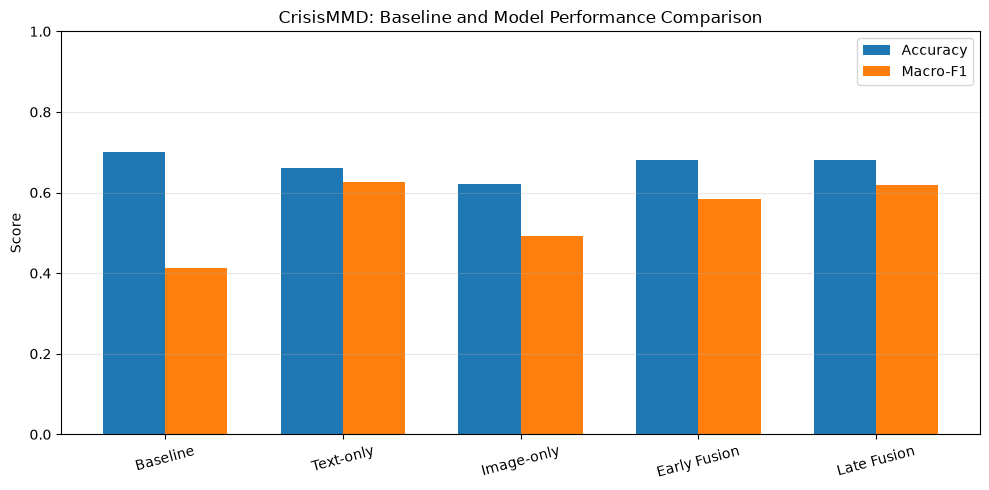

In [41]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "Baseline",
    "Text-only",
    "Image-only",
    "Early Fusion",
    "Late Fusion"
]

accuracy = [0.70, 0.66, 0.62, 0.68, 0.68]
macro_f1 = [0.4118, 0.6264, 0.4933, 0.5842, 0.6190]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, accuracy, width, label="Accuracy")
plt.bar(x + width/2, macro_f1, width, label="Macro-F1")

plt.xticks(x, models, rotation=15)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("CrisisMMD: Baseline and Model Performance Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

X_train = data["X_train_text"]
X_val = data["X_val_text"]
y_train = data["y_train"]
y_val = data["y_val"]

for C in [0.001, 0.01, 0.1, 1, 10]:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=C,
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    print(
        f"C={C:<6} "
        f"Train Acc={accuracy_score(y_train, train_pred):.3f} "
        f"Val Acc={accuracy_score(y_val, val_pred):.3f} "
        f"Val Macro-F1={f1_score(y_val, val_pred, average='macro'):.3f}"
    )

C=0.001  Train Acc=0.815 Val Acc=0.660 Val Macro-F1=0.587
C=0.01   Train Acc=0.925 Val Acc=0.660 Val Macro-F1=0.587
C=0.1    Train Acc=1.000 Val Acc=0.660 Val Macro-F1=0.616
C=1      Train Acc=1.000 Val Acc=0.660 Val Macro-F1=0.626
C=10     Train Acc=1.000 Val Acc=0.680 Val Macro-F1=0.653


In [43]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for C in [0.001, 0.01, 0.1, 1, 10]:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=C,
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro"
    )

    print(
        f"C={C:<6} "
        f"CV Macro-F1={scores.mean():.3f} "
        f"(±{scores.std():.3f})"
    )

C=0.001  CV Macro-F1=0.685 (±0.030)
C=0.01   CV Macro-F1=0.679 (±0.070)
C=0.1    CV Macro-F1=0.665 (±0.068)
C=1      CV Macro-F1=0.667 (±0.053)
C=10     CV Macro-F1=0.669 (±0.054)


In [44]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

best_text_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.001,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)

best_text_model.fit(X_train, y_train)

y_pred_text = best_text_model.predict(X_val)

print("Validation accuracy:",
      accuracy_score(y_val, y_pred_text))

print("Validation macro-F1:",
      f1_score(y_val, y_pred_text, average="macro"))

print("\nClassification report:")
print(classification_report(y_val, y_pred_text))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_pred_text))

Validation accuracy: 0.66
Validation macro-F1: 0.587178241864983

Classification report:
              precision    recall  f1-score   support

           0       0.75      0.77      0.76        35
           1       0.43      0.40      0.41        15

    accuracy                           0.66        50
   macro avg       0.59      0.59      0.59        50
weighted avg       0.65      0.66      0.66        50


Confusion matrix:
[[27  8]
 [ 9  6]]


# Full-Dataset Implementation and Final Evaluation

This section presents the final experiments using the complete
CrisisMMD dataset, consisting of 13,608 training samples,
2,237 validation samples and 2,237 test samples.

Unlike the preliminary pilot experiment, the final implementation
uses pretrained DistilBERT text embeddings and EfficientNet-B0
image embeddings extracted from the complete dataset.

Four classification approaches are evaluated:
text-only, image-only, early fusion and late fusion.

The development set is used for model comparison and selection,
while the held-out test set is used for final evaluation.

Additional analyses examine overfitting, classification errors,
computational efficiency, event-level performance and
class-specific limitations.

### Reproducibility and Saved Features

The final experiments use pretrained DistilBERT and EfficientNet-B0
models to extract 768-dimensional text embeddings and
1,280-dimensional image embeddings, respectively.

Feature extraction was performed in batches, and the resulting
embeddings were saved as NumPy (.npy) files to avoid repeating
computationally expensive extraction.

The saved embeddings are loaded in their original dataset order
for model training and evaluation.

Three classifiers (text-only, image-only and early fusion) are
trained using StandardScaler and LogisticRegression with
class_weight="balanced".

Late fusion combines the predicted probabilities of the
text-only and image-only classifiers using equal weighting.

The saved embeddings and trained classifiers are reusable
artifacts. Reproducing the complete workflow from scratch
requires access to the original dataset, preprocessing steps,
feature-extraction code and model configurations.

In [45]:
from datasets import load_dataset

dataset = load_dataset(
    "QCRI/CrisisMMD",
    "informative"
)

print("Available splits:", list(dataset.keys()))

for split in dataset:
    print(f"{split}: {len(dataset[split])} samples")

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Available splits: ['train', 'dev', 'test']
train: 13608 samples
dev: 2237 samples
test: 2237 samples


In [46]:
print("Dataset columns:")
print(dataset["train"].column_names)

print("\nFirst example:")
sample = dataset["train"][0]

for key, value in sample.items():
    print(key, ":", str(value)[:150])

Dataset columns:
['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label']

First example:
event_name : california_wildfires
tweet_id : 917791291823591425
image_id : 917791291823591425_0
tweet_text : RT @Cal_OES: PLS SHARE: Weâ€™re capturing wildfire response, recovery info here: https://t.co/r89LKpjLPj https://t.co/HiA1oQF2Ax
image_path : data_image/california_wildfires/10_10_2017/917791291823591425_0.jpg
image : None
label : 0


In [47]:
from collections import Counter

for split in ["train", "dev", "test"]:
    ds = dataset[split]

    missing_paths = sum(
        not row["image_path"] for row in ds
    )

    print(
        f"{split}: {len(ds)} records, "
        f"{missing_paths} missing image paths"
    )

train: 13608 records, 0 missing image paths
dev: 2237 records, 0 missing image paths
test: 2237 records, 0 missing image paths


In [48]:
import os
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
SAVE_DIR = str(PROJECT_DIR)

Path(SAVE_DIR).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Checkpoint folder ready:", SAVE_DIR)

Project directory: C:\Users\georg\CrisisMMD_Project
Checkpoint folder ready: C:\Users\georg\CrisisMMD_Project


In [49]:
from datasets import load_dataset

dataset = load_dataset("QCRI/CrisisMMD", "informative")

for split in ["train", "dev", "test"]:
    print(f"{split}: {len(dataset[split])} samples")

print("Total:", sum(len(dataset[s]) for s in dataset))

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


train: 13608 samples
dev: 2237 samples
test: 2237 samples
Total: 18082


In [50]:
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

text_model = AutoModel.from_pretrained(
    "distilbert-base-uncased"
).to(device)

text_model.eval()

print("DistilBERT loaded successfully!")

Using device: cuda


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT loaded successfully!


In [51]:
import numpy as np
import torch

def extract_text_features(texts, batch_size=16):
    all_features = []

    for start in range(0, len(texts), batch_size):
        batch = [
            str(t) if t is not None else ""
            for t in texts[start:start + batch_size]
        ]

        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        with torch.inference_mode():
            outputs = text_model(**inputs)

            # Attention-mask-aware mean pooling
            mask = inputs["attention_mask"].unsqueeze(-1)
            pooled = (
                (outputs.last_hidden_state * mask).sum(dim=1)
                / mask.sum(dim=1).clamp(min=1)
            )

        all_features.append(pooled.cpu().numpy())

    return np.vstack(all_features)

In [52]:
sample_texts = dataset["train"]["tweet_text"][:5]

sample_features = extract_text_features(
    sample_texts,
    batch_size=5
)

print("Feature shape:", sample_features.shape)
print("Expected shape: (5, 768)")
print("Contains NaN:", np.isnan(sample_features).any())

Feature shape: (5, 768)
Expected shape: (5, 768)
Contains NaN: False


In [53]:
import os
import numpy as np
from tqdm.auto import tqdm

text_dir = os.path.join(SAVE_DIR, "text_features")
os.makedirs(text_dir, exist_ok=True)

split = "train"
texts = dataset[split]["tweet_text"]
chunk_size = 500

for start in tqdm(range(0, len(texts), chunk_size)):
    end = min(start + chunk_size, len(texts))

    save_path = os.path.join(
        text_dir, f"{split}_{start}_{end}.npy"
    )

    # Skip chunks already saved
    if os.path.exists(save_path):
        continue

    features = extract_text_features(
        texts[start:end],
        batch_size=16
    )

    np.save(save_path, features)

print("Training text feature extraction completed!")

  0%|          | 0/28 [00:00<?, ?it/s]

Training text feature extraction completed!


In [54]:
split = "dev"
texts = dataset[split]["tweet_text"]
chunk_size = 500

for start in tqdm(range(0, len(texts), chunk_size)):
    end = min(start + chunk_size, len(texts))

    save_path = os.path.join(
        text_dir, f"{split}_{start}_{end}.npy"
    )

    # Skip previously completed chunks
    if os.path.exists(save_path):
        continue

    features = extract_text_features(
        texts[start:end],
        batch_size=16
    )

    np.save(save_path, features)

print("Validation text feature extraction completed!")

  0%|          | 0/5 [00:00<?, ?it/s]

Validation text feature extraction completed!


In [55]:
split = "test"
texts = dataset[split]["tweet_text"]
chunk_size = 500

for start in tqdm(range(0, len(texts), chunk_size)):
    end = min(start + chunk_size, len(texts))

    save_path = os.path.join(
        text_dir, f"{split}_{start}_{end}.npy"
    )

    # Skip chunks already saved
    if os.path.exists(save_path):
        continue

    features = extract_text_features(
        texts[start:end],
        batch_size=16
    )

    np.save(save_path, features)

print("Test text feature extraction completed!")

  0%|          | 0/5 [00:00<?, ?it/s]

Test text feature extraction completed!


In [56]:
import os
import numpy as np

for split in ["train", "dev", "test"]:
    files = [
        f for f in os.listdir(text_dir)
        if f.startswith(f"{split}_") and f.endswith(".npy")
    ]

    total = sum(
        np.load(os.path.join(text_dir, f)).shape[0]
        for f in files
    )

    expected = len(dataset[split])

    print(f"{split}: {total}/{expected} samples")
    print("Complete:", total == expected)
    print()

train: 13608/13608 samples
Complete: True

dev: 2237/2237 samples
Complete: True

test: 2237/2237 samples
Complete: True



In [57]:
print("Dataset columns:")
print(dataset["train"].column_names)

print("\nFirst sample image information:")
sample = dataset["train"][0]

for key, value in sample.items():
    if "image" in key.lower():
        print(key, ":", str(value)[:300])

print("\nGPU available:", torch.cuda.is_available())

Dataset columns:
['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label']

First sample image information:
image_id : 917791291823591425_0
image_path : data_image/california_wildfires/10_10_2017/917791291823591425_0.jpg
image : None

GPU available: True


Image downloaded successfully!
Image size: (640, 480)
Local path: 917791291823591425_0.jpg


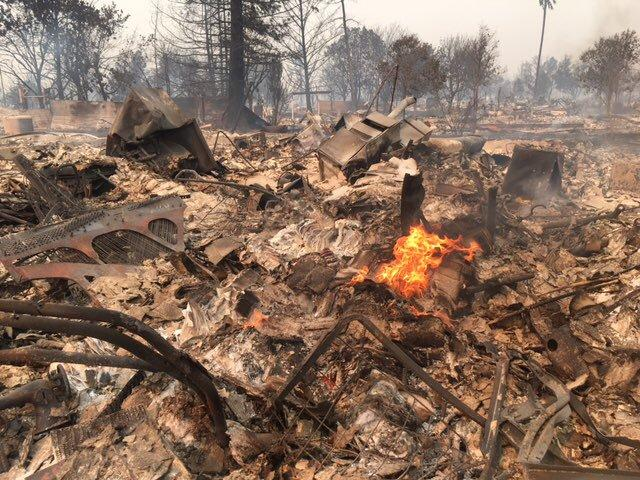

In [58]:
from huggingface_hub import hf_hub_download
from PIL import Image
import os

image_path = dataset["train"][0]["image_path"]

local_path = hf_hub_download(
    repo_id="QCRI/CrisisMMD",
    repo_type="dataset",
    filename=image_path
)

image = Image.open(local_path).convert("RGB")

print("Image downloaded successfully!")
print("Image size:", image.size)
print("Local path:", os.path.basename(local_path))

display(image)

In [59]:
import torch
import torchvision.models as models
from torchvision.models import EfficientNet_B0_Weights
import os

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = EfficientNet_B0_Weights.DEFAULT

image_model = models.efficientnet_b0(weights=weights)
image_model.classifier = torch.nn.Identity()
image_model = image_model.to(device)
image_model.eval()

image_transform = weights.transforms()

image_dir = os.path.join(os.getcwd(), "image_features")
os.makedirs(image_dir, exist_ok=True)

print("Device:", device)
print("Image model: EfficientNet-B0")
print("Feature dimension: 1280")
print("Feature folder:", image_dir)

Device: cuda
Image model: EfficientNet-B0
Feature dimension: 1280
Feature folder: C:\Users\georg\CrisisMMD_Project\image_features


In [60]:
import numpy as np
from tqdm.auto import tqdm
from PIL import Image
from huggingface_hub import hf_hub_download

split = "train"
chunk_size = 100
batch_size = 16

def extract_image_features(paths):
    all_features = []

    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start:start + batch_size]
        images = []

        for path in batch_paths:
            local_path = hf_hub_download(
                repo_id="QCRI/CrisisMMD",
                repo_type="dataset",
                filename=path
            )

            with Image.open(local_path) as img:
                images.append(
                    image_transform(img.convert("RGB"))
                )

        batch = torch.stack(images).to(device)

        with torch.inference_mode():
            features = image_model(batch)

        all_features.append(features.cpu().numpy())

    return np.concatenate(all_features, axis=0)


paths = dataset[split]["image_path"]

for start in tqdm(range(0, len(paths), chunk_size)):
    end = min(start + chunk_size, len(paths))

    save_path = os.path.join(
        image_dir, f"{split}_{start}_{end}.npy"
    )

    if os.path.exists(save_path):
        continue

    features = extract_image_features(paths[start:end])
    np.save(save_path, features)

print("Training image feature extraction completed!")

  0%|          | 0/137 [00:00<?, ?it/s]

Training image feature extraction completed!


In [61]:
from datasets import load_dataset

dataset = load_dataset(
    "QCRI/CrisisMMD",
    "informative"
)

print(dataset)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


DatasetDict({
    train: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 13608
    })
    dev: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 2237
    })
    test: Dataset({
        features: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label'],
        num_rows: 2237
    })
})


In [62]:
import os
import torch
import torchvision.models as models
from torchvision.models import EfficientNet_B0_Weights

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = EfficientNet_B0_Weights.DEFAULT

image_model = models.efficientnet_b0(weights=weights)
image_model.classifier = torch.nn.Identity()
image_model = image_model.to(device)
image_model.eval()

image_transform = weights.transforms()

image_dir = os.path.join(os.getcwd(), "image_features")
os.makedirs(image_dir, exist_ok=True)

print("Device:", device)
print("Model: EfficientNet-B0")
print("Feature dimension: 1280")
print("Saved feature folder:", image_dir)

saved_chunks = [
    f for f in os.listdir(image_dir)
    if f.startswith("train_") and f.endswith(".npy")
]

print("Previously saved training chunks:", len(saved_chunks))

Device: cuda
Model: EfficientNet-B0
Feature dimension: 1280
Saved feature folder: C:\Users\georg\CrisisMMD_Project\image_features
Previously saved training chunks: 137


In [63]:
import os
import numpy as np

valid = 0
invalid = []

for start in range(0, len(dataset["train"]), 100):
    end = min(start + 100, len(dataset["train"]))
    filename = f"train_{start}_{end}.npy"
    path = os.path.join(image_dir, filename)

    if not os.path.exists(path):
        continue

    try:
        features = np.load(path)
        if features.shape == (end - start, 1280) and np.isfinite(features).all():
            valid += 1
        else:
            invalid.append(filename)
    except Exception:
        invalid.append(filename)

print("Valid chunks:", valid)
print("Invalid chunks:", invalid)
print("Remaining chunks:", 137 - valid)

Valid chunks: 137
Invalid chunks: []
Remaining chunks: 0


In [64]:
import torch
import sys

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: C:\Users\georg\anaconda3\python.exe
PyTorch: 2.14.1+cu126
GPU available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [65]:
import numpy as np
from tqdm.auto import tqdm
from PIL import Image
from huggingface_hub import hf_hub_download

def extract_image_features(paths, batch_size=16):
    all_features = []

    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start:start + batch_size]
        images = []

        for path in batch_paths:
            local_path = hf_hub_download(
                repo_id="QCRI/CrisisMMD",
                repo_type="dataset",
                filename=path
            )

            with Image.open(local_path) as img:
                images.append(
                    image_transform(img.convert("RGB"))
                )

        batch = torch.stack(images).to(device)

        with torch.inference_mode():
            features = image_model(batch)

        all_features.append(features.cpu().numpy())

    return np.concatenate(all_features, axis=0)


split = "train"
chunk_size = 100
paths = dataset[split]["image_path"]

for start in tqdm(range(0, len(paths), chunk_size)):
    end = min(start + chunk_size, len(paths))
    save_path = os.path.join(
        image_dir, f"{split}_{start}_{end}.npy"
    )

    if os.path.exists(save_path):
        continue

    features = extract_image_features(paths[start:end])
    np.save(save_path, features)

print("Training image feature extraction completed!")

  0%|          | 0/137 [00:00<?, ?it/s]

Training image feature extraction completed!


In [66]:
import os
import numpy as np

valid = 0
invalid = []

for start in range(0, len(dataset["train"]), 100):
    end = min(start + 100, len(dataset["train"]))
    filename = f"train_{start}_{end}.npy"
    path = os.path.join(image_dir, filename)

    try:
        features = np.load(path)
        if features.shape == (end - start, 1280) and np.isfinite(features).all():
            valid += 1
        else:
            invalid.append(filename)
    except Exception:
        invalid.append(filename)

print("Valid chunks:", valid)
print("Invalid chunks:", invalid)
print("All training features saved:", valid == 137)

Valid chunks: 137
Invalid chunks: []
All training features saved: True


In [67]:
from tqdm.auto import tqdm
import os
import numpy as np

split = "dev"
chunk_size = 100
paths = dataset[split]["image_path"]

for start in tqdm(range(0, len(paths), chunk_size)):
    end = min(start + chunk_size, len(paths))

    save_path = os.path.join(
        image_dir, f"{split}_{start}_{end}.npy"
    )

    if os.path.exists(save_path):
        continue

    features = extract_image_features(paths[start:end])

    np.save(save_path, features)

print("Validation image feature extraction completed!")

  0%|          | 0/23 [00:00<?, ?it/s]

Validation image feature extraction completed!


In [68]:
import os
import numpy as np
from tqdm.auto import tqdm

# Uses your existing:
# dataset, image_dir, extract_image_features

chunk_size = 100

for split in ["dev", "test"]:
    paths = dataset[split]["image_path"]

    print(f"\nProcessing {split}: {len(paths)} images")

    for start in tqdm(range(0, len(paths), chunk_size),
                      desc=f"{split} images"):

        end = min(start + chunk_size, len(paths))

        save_path = os.path.join(
            image_dir, f"{split}_{start}_{end}.npy"
        )

        # Check existing chunks before skipping
        if os.path.exists(save_path):
            try:
                existing = np.load(save_path)
                if (
                    existing.shape == (end - start, 1280)
                    and np.isfinite(existing).all()
                ):
                    continue
            except Exception:
                pass

        features = extract_image_features(paths[start:end])

        assert features.shape == (end - start, 1280)

        # Save atomically to avoid partially written chunks
        temp_path = save_path + ".tmp.npy"
        np.save(temp_path, features)
        os.replace(temp_path, save_path)

    print(f"{split} image extraction completed!")


Processing dev: 2237 images


dev images:   0%|          | 0/23 [00:00<?, ?it/s]

dev image extraction completed!

Processing test: 2237 images


test images:   0%|          | 0/23 [00:00<?, ?it/s]

test image extraction completed!


In [69]:
from pathlib import Path

base = PROJECT_DIR

print("Text feature folders:")
for folder in base.iterdir():
    if folder.is_dir() and "text" in folder.name.lower():
        print(folder)

print("\nSaved text feature files:")
for file in base.rglob("train_0_500.npy"):
    print(file)

Text feature folders:
C:\Users\georg\CrisisMMD_Project\text_features

Saved text feature files:
C:\Users\georg\CrisisMMD_Project\text_features\train_0_500.npy


In [70]:
from pathlib import Path
import numpy as np

base = PROJECT_DIR

pilot_file = base / "crisismmd_features.npz"

print("Checking:", pilot_file)
print("File exists:", pilot_file.exists())

if pilot_file.exists():
    with np.load(pilot_file) as data:
        for key in data.files:
            print(key, data[key].shape)

Checking: C:\Users\georg\CrisisMMD_Project\crisismmd_features.npz
File exists: True
X_train_text (200, 768)
X_val_text (50, 768)
X_train_image (200, 1280)
X_val_image (50, 1280)
y_train (200,)
y_val (50,)


In [71]:
from pathlib import Path

base = PROJECT_DIR

folder = base / "text_features"

print("Checking:", folder)
print("Folder exists:", folder.exists())

for split in ["train", "dev", "test"]:
    files = sorted(folder.glob(f"{split}_*.npy"))
    print(f"{split}: {len(files)} chunks")

Checking: C:\Users\georg\CrisisMMD_Project\text_features
Folder exists: True
train: 28 chunks
dev: 5 chunks
test: 5 chunks


In [72]:
from pathlib import Path

folder = PROJECT_DIR / "image_features"

for split in ["train", "dev", "test"]:
    files = list(folder.glob(f"{split}_*.npy"))
    print(f"{split}: {len(files)} chunks")

train: 137 chunks
dev: 23 chunks
test: 23 chunks


In [73]:
from pathlib import Path

folder = PROJECT_DIR / "image_features"

print("Checking:", folder)
print("Folder exists:", folder.exists())

for split in ["train", "dev", "test"]:
    files = sorted(folder.glob(f"{split}_*.npy"))
    print(f"{split}: {len(files)} chunks")

Checking: C:\Users\georg\CrisisMMD_Project\image_features
Folder exists: True
train: 137 chunks
dev: 23 chunks
test: 23 chunks


In [74]:
print("Dataset loaded:", "dataset" in globals())
print("Text extraction function:", "extract_text_features" in globals())
print("Text directory variable:", "text_dir" in globals())

if "text_dir" in globals():
    print("Text directory:", text_dir)

Dataset loaded: True
Text extraction function: True
Text directory variable: True
Text directory: C:\Users\georg\CrisisMMD_Project\text_features


In [75]:
import os
from pathlib import Path

text_dir = PROJECT_DIR / "text_features"
text_dir.mkdir(parents=True, exist_ok=True)

print("Text feature directory:", text_dir)
print("Folder exists:", text_dir.exists())

for split in ["train", "dev", "test"]:
    files = list(text_dir.glob(f"{split}_*.npy"))
    print(f"{split}: {len(files)} saved chunks")

Text feature directory: C:\Users\georg\CrisisMMD_Project\text_features
Folder exists: True
train: 28 saved chunks
dev: 5 saved chunks
test: 5 saved chunks


In [76]:
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

text_model = AutoModel.from_pretrained(model_name)
text_model = text_model.to(device)
text_model.eval()

print("Device:", device)
print("Model:", model_name)
print("Feature dimension:", text_model.config.hidden_size)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda
Model: distilbert-base-uncased
Feature dimension: 768


In [77]:
import numpy as np
import torch
from tqdm.auto import tqdm

def extract_text_features(texts, batch_size=32):
    all_features = []

    for start in tqdm(range(0, len(texts), batch_size)):
        batch_texts = [
            str(t) if t is not None else ""
            for t in texts[start:start + batch_size]
        ]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = text_model(**inputs)

            mask = inputs["attention_mask"].unsqueeze(-1)

            embeddings = (
                (outputs.last_hidden_state * mask).sum(dim=1)
                / mask.sum(dim=1).clamp(min=1)
            )

        all_features.append(embeddings.cpu().numpy())

    return np.concatenate(all_features, axis=0)

In [78]:
# Select 5 tweets from the training dataset
sample_texts = dataset["train"]["tweet_text"][:5]

# Extract text features
sample_features = extract_text_features(sample_texts)

print("Number of tweets:", len(sample_texts))
print("Feature shape:", sample_features.shape)
print("Contains NaN:", np.isnan(sample_features).any())

  0%|          | 0/1 [00:00<?, ?it/s]

Number of tweets: 5
Feature shape: (5, 768)
Contains NaN: False


In [79]:
from pathlib import Path
import numpy as np

text_dir = PROJECT_DIR / "text_features"
text_dir.mkdir(parents=True, exist_ok=True)

split = "train"
chunk_size = 500

texts = dataset[split]["tweet_text"]

for start in range(0, len(texts), chunk_size):
    end = min(start + chunk_size, len(texts))
    save_path = text_dir / f"{split}_{start}_{end}.npy"

    if save_path.exists():
        print(f"Skipping existing: {save_path.name}")
        continue

    features = extract_text_features(
        texts[start:end],
        batch_size=32
    )

    np.save(save_path, features)
    print(f"Saved: {save_path.name} | Shape: {features.shape}")

print("Training text feature extraction completed!")

Skipping existing: train_0_500.npy
Skipping existing: train_500_1000.npy
Skipping existing: train_1000_1500.npy
Skipping existing: train_1500_2000.npy
Skipping existing: train_2000_2500.npy
Skipping existing: train_2500_3000.npy
Skipping existing: train_3000_3500.npy
Skipping existing: train_3500_4000.npy
Skipping existing: train_4000_4500.npy
Skipping existing: train_4500_5000.npy
Skipping existing: train_5000_5500.npy
Skipping existing: train_5500_6000.npy
Skipping existing: train_6000_6500.npy
Skipping existing: train_6500_7000.npy
Skipping existing: train_7000_7500.npy
Skipping existing: train_7500_8000.npy
Skipping existing: train_8000_8500.npy
Skipping existing: train_8500_9000.npy
Skipping existing: train_9000_9500.npy
Skipping existing: train_9500_10000.npy
Skipping existing: train_10000_10500.npy
Skipping existing: train_10500_11000.npy
Skipping existing: train_11000_11500.npy
Skipping existing: train_11500_12000.npy
Skipping existing: train_12000_12500.npy
Skipping existing: 

In [80]:
import numpy as np

chunk_size = 500

for split in ["dev", "test"]:
    texts = dataset[split]["tweet_text"]

    print(f"\nProcessing {split}: {len(texts)} tweets")

    for start in range(0, len(texts), chunk_size):
        end = min(start + chunk_size, len(texts))
        save_path = text_dir / f"{split}_{start}_{end}.npy"

        if save_path.exists():
            print(f"Skipping existing: {save_path.name}")
            continue

        features = extract_text_features(
            texts[start:end],
            batch_size=32
        )

        np.save(save_path, features)
        print(f"Saved: {save_path.name} | Shape: {features.shape}")

    print(f"{split.upper()} text extraction completed!")

print("\nAll validation and test text features saved!")


Processing dev: 2237 tweets
Skipping existing: dev_0_500.npy
Skipping existing: dev_500_1000.npy
Skipping existing: dev_1000_1500.npy
Skipping existing: dev_1500_2000.npy
Skipping existing: dev_2000_2237.npy
DEV text extraction completed!

Processing test: 2237 tweets
Skipping existing: test_0_500.npy
Skipping existing: test_500_1000.npy
Skipping existing: test_1000_1500.npy
Skipping existing: test_1500_2000.npy
Skipping existing: test_2000_2237.npy
TEST text extraction completed!

All validation and test text features saved!


In [81]:
from datasets import load_dataset

dataset = load_dataset("QCRI/CrisisMMD", "informative")

print("Dataset loaded successfully!")

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Dataset loaded successfully!


In [82]:
import numpy as np
from pathlib import Path

text_dir = PROJECT_DIR / "text_features"
image_dir = PROJECT_DIR / "image_features"

for split in ["train", "dev", "test"]:

    expected = len(dataset[split])

    results = {}

    for name, folder in [
        ("Text", text_dir),
        ("Image", image_dir)
    ]:
        files = sorted(
            folder.glob(f"{split}_*.npy"),
            key=lambda p: int(p.stem.split("_")[1])
        )

        total_rows = 0
        dimensions = set()
        ranges = []

        for file in files:
            parts = file.stem.split("_")
            start, end = int(parts[1]), int(parts[2])

            arr = np.load(file, mmap_mode="r")

            total_rows += arr.shape[0]
            dimensions.add(arr.shape[1])
            ranges.append((start, end))

        ranges_valid = (
            ranges == [
                (start, min(start + (500 if name == "Text" else 100), expected))
                for start in range(
                    0, expected,
                    500 if name == "Text" else 100
                )
            ]
        )

        results[name] = total_rows

        print(
            f"{split.upper()} {name}: "
            f"{len(files)} chunks, "
            f"{total_rows} rows, "
            f"dimensions={dimensions}, "
            f"ranges valid={ranges_valid}"
        )

    print(f"Expected samples: {expected}")
    print(
        "Row counts match:",
        results["Text"] == results["Image"] == expected
    )
    print("-" * 50)

TRAIN Text: 28 chunks, 13608 rows, dimensions={768}, ranges valid=True
TRAIN Image: 137 chunks, 13608 rows, dimensions={1280}, ranges valid=True
Expected samples: 13608
Row counts match: True
--------------------------------------------------
DEV Text: 5 chunks, 2237 rows, dimensions={768}, ranges valid=True
DEV Image: 23 chunks, 2237 rows, dimensions={1280}, ranges valid=True
Expected samples: 2237
Row counts match: True
--------------------------------------------------
TEST Text: 5 chunks, 2237 rows, dimensions={768}, ranges valid=True
TEST Image: 23 chunks, 2237 rows, dimensions={1280}, ranges valid=True
Expected samples: 2237
Row counts match: True
--------------------------------------------------


In [83]:
import numpy as np

def load_features(folder, split):
    files = sorted(
        folder.glob(f"{split}_*.npy"),
        key=lambda p: int(p.stem.split("_")[1])
    )

    arrays = [np.load(file) for file in files]

    return np.concatenate(arrays, axis=0)

X_train_text = load_features(text_dir, "train")
X_dev_text = load_features(text_dir, "dev")

X_train_image = load_features(image_dir, "train")
X_dev_image = load_features(image_dir, "dev")

y_train = np.array(dataset["train"]["label"])
y_dev = np.array(dataset["dev"]["label"])

print("Training text:", X_train_text.shape)
print("Training image:", X_train_image.shape)
print("Training labels:", y_train.shape)

print("Validation text:", X_dev_text.shape)
print("Validation image:", X_dev_image.shape)
print("Validation labels:", y_dev.shape)

print("Unique labels:", np.unique(y_train, return_counts=True))

Training text: (13608, 768)
Training image: (13608, 1280)
Training labels: (13608,)
Validation text: (2237, 768)
Validation image: (2237, 1280)
Validation labels: (2237,)
Unique labels: (array([0, 1]), array([8341, 5267]))


In [84]:
print("Dataset features:")
print(dataset["train"].features)

print("\nFirst 5 training examples:")

for i in range(5):
    example = dataset["train"][i]

    print(f"\nExample {i + 1}")
    print("Label:", example["label"])
    print("Tweet:", example["tweet_text"][:200])
    print("Event:", example["event_name"])

Dataset features:
{'event_name': Value('string'), 'tweet_id': Value('string'), 'image_id': Value('string'), 'tweet_text': Value('string'), 'image_path': Value('string'), 'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['informative', 'not_informative'])}

First 5 training examples:

Example 1
Label: 0
Tweet: RT @Cal_OES: PLS SHARE: Weâ€™re capturing wildfire response, recovery info here: https://t.co/r89LKpjLPj https://t.co/HiA1oQF2Ax
Event: california_wildfires

Example 2
Label: 1
Tweet: RT @Cal_OES: PLS SHARE: Weâ€™re capturing wildfire response, recovery info here: https://t.co/r89LKpjLPj https://t.co/HiA1oQF2Ax
Event: california_wildfires

Example 3
Label: 0
Tweet: RT @KAKEnews: California wildfires destroy more than 50 structures: https://t.co/IkSrNpmT83 #KAKEnews https://t.co/8risKwbBqr
Event: california_wildfires

Example 4
Label: 0
Tweet: RT @KAKEnews: California wildfires destroy more than 50 structures: https://t.co/IkSrNpmT83 #KAKEnews https://t.co/8risKwbB

In [85]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

text_clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

# Train on training data only
text_clf.fit(X_train_text, y_train)

# Evaluate on validation data
y_dev_pred_text = text_clf.predict(X_dev_text)

print("TEXT-ONLY BASELINE RESULTS")
print("--------------------------")
print("Accuracy:", round(accuracy_score(y_dev, y_dev_pred_text), 4))
print("Macro-F1:", round(f1_score(y_dev, y_dev_pred_text, average="macro"), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_dev,
        y_dev_pred_text,
        target_names=["Informative", "Not informative"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_dev, y_dev_pred_text))

TEXT-ONLY BASELINE RESULTS
--------------------------
Accuracy: 0.6969
Macro-F1: 0.6808

Classification Report:
                 precision    recall  f1-score   support

    Informative       0.77      0.73      0.75      1407
Not informative       0.58      0.64      0.61       830

       accuracy                           0.70      2237
      macro avg       0.68      0.68      0.68      2237
   weighted avg       0.70      0.70      0.70      2237


Confusion Matrix:
[[1031  376]
 [ 302  528]]


In [86]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

image_clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

# Train using image features only
image_clf.fit(X_train_image, y_train)

# Predict on validation dataset
y_dev_pred_image = image_clf.predict(X_dev_image)

print("IMAGE-ONLY BASELINE RESULTS")
print("---------------------------")

print(
    "Accuracy:",
    round(accuracy_score(y_dev, y_dev_pred_image), 4)
)

print(
    "Macro-F1:",
    round(f1_score(y_dev, y_dev_pred_image, average="macro"), 4)
)

print("\nClassification Report:")
print(
    classification_report(
        y_dev,
        y_dev_pred_image,
        target_names=["Informative", "Not informative"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_dev, y_dev_pred_image))

IMAGE-ONLY BASELINE RESULTS
---------------------------
Accuracy: 0.7139
Macro-F1: 0.7026

Classification Report:
                 precision    recall  f1-score   support

    Informative       0.80      0.72      0.76      1407
Not informative       0.60      0.70      0.64       830

       accuracy                           0.71      2237
      macro avg       0.70      0.71      0.70      2237
   weighted avg       0.73      0.71      0.72      2237


Confusion Matrix:
[[1017  390]
 [ 250  580]]


In [87]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix
)
import numpy as np

# Combine text and image features
X_train_early = np.concatenate(
    [X_train_text, X_train_image], axis=1
)

X_dev_early = np.concatenate(
    [X_dev_text, X_dev_image], axis=1
)

print("Training shape:", X_train_early.shape)
print("Validation shape:", X_dev_early.shape)

# Train early-fusion classifier
early_clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

early_clf.fit(X_train_early, y_train)

# Evaluate on validation set
y_dev_pred_early = early_clf.predict(X_dev_early)

print("\nEARLY-FUSION RESULTS")
print("--------------------")
print("Accuracy:", round(
    accuracy_score(y_dev, y_dev_pred_early), 4
))
print("Macro-F1:", round(
    f1_score(y_dev, y_dev_pred_early, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_dev, y_dev_pred_early,
    target_names=["Informative", "Not informative"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_dev, y_dev_pred_early))

Training shape: (13608, 2048)
Validation shape: (2237, 2048)

EARLY-FUSION RESULTS
--------------------
Accuracy: 0.7336
Macro-F1: 0.72

Classification Report:
                 precision    recall  f1-score   support

    Informative       0.81      0.76      0.78      1407
Not informative       0.63      0.69      0.66       830

       accuracy                           0.73      2237
      macro avg       0.72      0.72      0.72      2237
   weighted avg       0.74      0.73      0.74      2237


Confusion Matrix:
[[1067  340]
 [ 256  574]]


In [88]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

# Obtain probabilities from both trained baseline models
text_probs = text_clf.predict_proba(X_dev_text)
image_probs = image_clf.predict_proba(X_dev_image)

# Ensure both models use the same class ordering
assert np.array_equal(text_clf.classes_, image_clf.classes_)

# Equal-weight late fusion
late_probs = 0.5 * text_probs + 0.5 * image_probs

# Choose the class with the highest combined probability
y_dev_pred_late = text_clf.classes_[
    np.argmax(late_probs, axis=1)
]

print("LATE-FUSION RESULTS")
print("-------------------")

print("Accuracy:", round(
    accuracy_score(y_dev, y_dev_pred_late), 4
))

print("Macro-F1:", round(
    f1_score(y_dev, y_dev_pred_late, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_dev,
    y_dev_pred_late,
    target_names=["Informative", "Not informative"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_dev, y_dev_pred_late))

LATE-FUSION RESULTS
-------------------
Accuracy: 0.7488
Macro-F1: 0.7344

Classification Report:
                 precision    recall  f1-score   support

    Informative       0.81      0.78      0.80      1407
Not informative       0.65      0.70      0.67       830

       accuracy                           0.75      2237
      macro avg       0.73      0.74      0.73      2237
   weighted avg       0.75      0.75      0.75      2237


Confusion Matrix:
[[1098  309]
 [ 253  577]]


In [89]:
def get_tweet_ids(split):
    return set(dataset[split]["tweet_id"])

train_ids = get_tweet_ids("train")
dev_ids = get_tweet_ids("dev")
test_ids = get_tweet_ids("test")

print("Train–Dev overlap:", len(train_ids & dev_ids))
print("Train–Test overlap:", len(train_ids & test_ids))
print("Dev–Test overlap:", len(dev_ids & test_ids))

print("\nUnique tweet IDs:")
for split in ["train", "dev", "test"]:
    print(split, len(get_tweet_ids(split)))

Train–Dev overlap: 0
Train–Test overlap: 0
Dev–Test overlap: 0

Unique tweet IDs:
train 11584
dev 2237
test 2237


In [90]:
import pandas as pd

train_df = pd.DataFrame({
    "tweet_id": dataset["train"]["tweet_id"],
    "image_id": dataset["train"]["image_id"],
    "label": dataset["train"]["label"]
})

# Find duplicated tweet IDs
duplicate_rows = train_df[
    train_df.duplicated("tweet_id", keep=False)
]

# Count tweet IDs with conflicting labels
label_counts = train_df.groupby("tweet_id")["label"].nunique()
conflicting_ids = label_counts[label_counts > 1]

print("Total training samples:", len(train_df))
print("Unique tweet IDs:", train_df["tweet_id"].nunique())
print("Rows involving duplicated tweet IDs:", len(duplicate_rows))
print("Tweet IDs with conflicting labels:", len(conflicting_ids))

print("\nExample duplicate records:")
print(duplicate_rows.head(10).to_string(index=False))

Total training samples: 13608
Unique tweet IDs: 11584
Rows involving duplicated tweet IDs: 3169
Tweet IDs with conflicting labels: 283

Example duplicate records:
          tweet_id             image_id  label
917791291823591425 917791291823591425_0      0
917791291823591425 917791291823591425_1      1
917793137925459968 917793137925459968_0      0
917793137925459968 917793137925459968_1      0
917793137925459968 917793137925459968_2      0
917815040962695168 917815040962695168_0      0
917815040962695168 917815040962695168_1      0
917815040962695168 917815040962695168_2      0
917828283047260161 917828283047260161_0      0
917828283047260161 917828283047260161_1      0


In [91]:
# Check repeated tweet-image pairs
pair_counts = train_df.groupby(
    ["tweet_id", "image_id"]
).size()

duplicate_pairs = pair_counts[pair_counts > 1]

# Check label conflicts for identical pairs
pair_label_counts = train_df.groupby(
    ["tweet_id", "image_id"]
)["label"].nunique()

conflicting_pairs = pair_label_counts[
    pair_label_counts > 1
]

print("Duplicate tweet-image pairs:", len(duplicate_pairs))
print("Pairs with conflicting labels:", len(conflicting_pairs))

print("\nUnique image IDs:", train_df["image_id"].nunique())
print("Total training samples:", len(train_df))

Duplicate tweet-image pairs: 0
Pairs with conflicting labels: 0

Unique image IDs: 13608
Total training samples: 13608


In [92]:
# Load saved test embeddings
X_test_text = load_features(text_dir, "test")
X_test_image = load_features(image_dir, "test")

# Load test labels
y_test = np.array(dataset["test"]["label"])

print("Test text features:", X_test_text.shape)
print("Test image features:", X_test_image.shape)
print("Test labels:", y_test.shape)

# Verify alignment
assert len(X_test_text) == len(X_test_image) == len(y_test)

print("\nTest dataset loaded successfully!")
print("Label distribution:", np.unique(y_test, return_counts=True))

Test text features: (2237, 768)
Test image features: (2237, 1280)
Test labels: (2237,)

Test dataset loaded successfully!
Label distribution: (array([0, 1]), array([1373,  864]))


In [93]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

# Get test probabilities from the trained models
test_text_probs = text_clf.predict_proba(X_test_text)
test_image_probs = image_clf.predict_proba(X_test_image)

# Verify class ordering
assert np.array_equal(text_clf.classes_, image_clf.classes_)

# Apply the previously selected 50/50 late fusion
test_late_probs = (
    0.5 * test_text_probs +
    0.5 * test_image_probs
)

# Final predictions
y_test_pred_late = text_clf.classes_[
    np.argmax(test_late_probs, axis=1)
]

print("FINAL TEST RESULTS — LATE FUSION")
print("--------------------------------")

print("Accuracy:", round(
    accuracy_score(y_test, y_test_pred_late), 4
))

print("Macro-F1:", round(
    f1_score(y_test, y_test_pred_late, average="macro"), 4
))

print("Macro Precision:", round(
    precision_score(y_test, y_test_pred_late, average="macro"), 4
))

print("Macro Recall:", round(
    recall_score(y_test, y_test_pred_late, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_late,
    target_names=["Informative", "Not informative"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_late))

FINAL TEST RESULTS — LATE FUSION
--------------------------------
Accuracy: 0.7653
Macro-F1: 0.7564
Macro Precision: 0.7538
Macro Recall: 0.7612

Classification Report:
                 precision    recall  f1-score   support

    Informative       0.83      0.78      0.80      1373
Not informative       0.68      0.74      0.71       864

       accuracy                           0.77      2237
      macro avg       0.75      0.76      0.76      2237
   weighted avg       0.77      0.77      0.77      2237


Confusion Matrix:
[[1070  303]
 [ 222  642]]


In [94]:
import joblib
import json
from pathlib import Path

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(text_clf, results_dir / "text_model.joblib")
joblib.dump(image_clf, results_dir / "image_model.joblib")
joblib.dump(early_clf, results_dir / "early_fusion_model.joblib")

metrics = {
    "model": "Late fusion",
    "fusion_weights": {"text": 0.5, "image": 0.5},
    "test_accuracy": float(accuracy_score(y_test, y_test_pred_late)),
    "test_macro_f1": float(f1_score(y_test, y_test_pred_late, average="macro")),
    "test_macro_precision": float(precision_score(y_test, y_test_pred_late, average="macro")),
    "test_macro_recall": float(recall_score(y_test, y_test_pred_late, average="macro")),
    "test_confusion_matrix": confusion_matrix(y_test, y_test_pred_late).tolist()
}

with open(results_dir / "final_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Models and final results saved successfully!")
print("Location:", results_dir)

Models and final results saved successfully!
Location: C:\Users\georg\CrisisMMD_Project\results


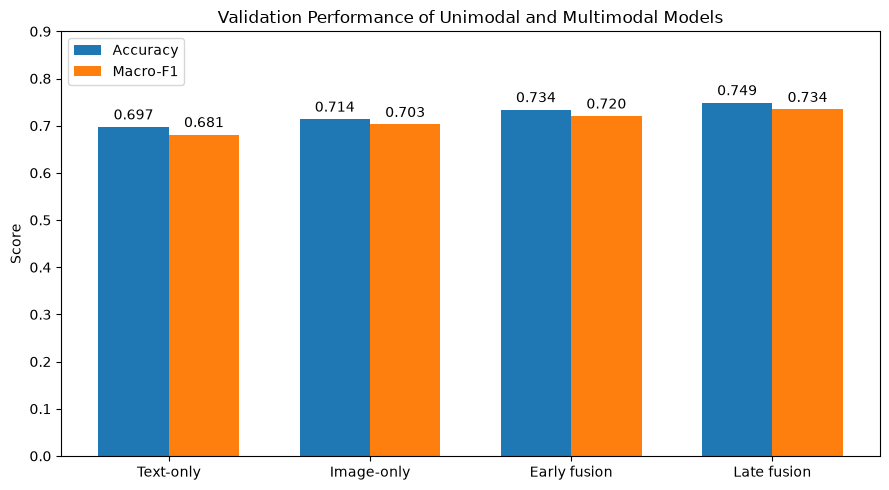

Comparison chart saved successfully!


In [95]:
import matplotlib.pyplot as plt
from pathlib import Path

models = ["Text-only", "Image-only", "Early fusion", "Late fusion"]
macro_f1 = [0.6812, 0.7026, 0.7204, 0.7344]
accuracy = [0.6974, 0.7139, 0.7340, 0.7488]

fig, ax = plt.subplots(figsize=(9, 5))

x = range(len(models))
width = 0.35

bars1 = ax.bar(
    [i - width/2 for i in x],
    accuracy,
    width,
    label="Accuracy"
)

bars2 = ax.bar(
    [i + width/2 for i in x],
    macro_f1,
    width,
    label="Macro-F1"
)

ax.set_xticks(list(x))
ax.set_xticklabels(models)
ax.set_ylabel("Score")
ax.set_title("Validation Performance of Unimodal and Multimodal Models")
ax.set_ylim(0, 0.9)
ax.legend()

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

plt.tight_layout()

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(results_dir / "model_comparison.png", dpi=300)
plt.show()

print("Comparison chart saved successfully!")

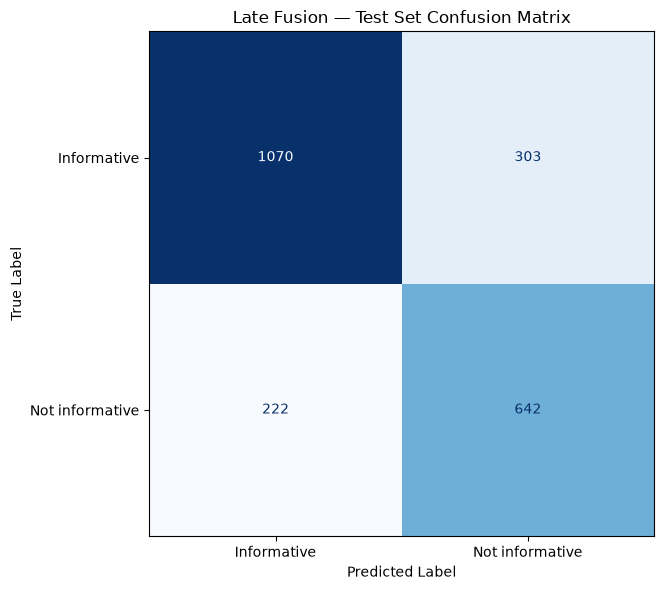

Confusion matrix saved successfully!


In [96]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Calculate confusion matrix using final test predictions
cm = confusion_matrix(y_test, y_test_pred_late)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Informative", "Not informative"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Late Fusion — Test Set Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()

plt.savefig(
    results_dir / "late_fusion_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

In [97]:
import joblib
from pathlib import Path

results_dir = PROJECT_DIR / "results"

text_clf = joblib.load(results_dir / "text_model.joblib")
image_clf = joblib.load(results_dir / "image_model.joblib")
early_clf = joblib.load(results_dir / "early_fusion_model.joblib")

print("All three models loaded successfully!")

All three models loaded successfully!


In [98]:
variables = [
    "X_train_text",
    "X_dev_text",
    "X_train_image",
    "X_dev_image",
    "X_train_early",
    "X_dev_early",
    "y_train",
    "y_dev"
]

for name in variables:
    if name in globals():
        print(f"{name}: FOUND {globals()[name].shape}")
    else:
        print(f"{name}: NOT LOADED")

X_train_text: FOUND (13608, 768)
X_dev_text: FOUND (2237, 768)
X_train_image: FOUND (13608, 1280)
X_dev_image: FOUND (2237, 1280)
X_train_early: FOUND (13608, 2048)
X_dev_early: FOUND (2237, 2048)
y_train: FOUND (13608,)
y_dev: FOUND (2237,)


In [99]:
from pathlib import Path

base = PROJECT_DIR

for folder_name in ["text_features", "image_features"]:
    folder = base / folder_name

    print(f"\n{folder_name}")
    print("Folder exists:", folder.exists())

    files = sorted(folder.glob("*.npy"))

    print("Number of files:", len(files))
    print("First 5 filenames:")

    for file in files[:5]:
        print(" ", file.name)


text_features
Folder exists: True
Number of files: 38
First 5 filenames:
  dev_0_500.npy
  dev_1000_1500.npy
  dev_1500_2000.npy
  dev_2000_2237.npy
  dev_500_1000.npy

image_features
Folder exists: True
Number of files: 183
First 5 filenames:
  dev_0_100.npy
  dev_1000_1100.npy
  dev_100_200.npy
  dev_1100_1200.npy
  dev_1200_1300.npy


In [100]:
import numpy as np
from pathlib import Path

base = PROJECT_DIR

text_dir = base / "text_features"
image_dir = base / "image_features"

def load_features(folder, split):
    files = sorted(
        folder.glob(f"{split}_*.npy"),
        key=lambda p: int(p.stem.split("_")[1])
    )

    if not files:
        raise FileNotFoundError(
            f"No {split} files found in {folder}"
        )

    # Check that chunks are in the correct order
    expected_start = 0

    for file in files:
        parts = file.stem.split("_")
        start, end = int(parts[1]), int(parts[2])

        if start != expected_start:
            raise ValueError(
                f"Missing or overlapping chunk before {file.name}"
            )

        expected_start = end

    features = np.concatenate(
        [np.load(file) for file in files],
        axis=0
    )

    return features

# Load text embeddings
X_train_text = load_features(text_dir, "train")
X_dev_text = load_features(text_dir, "dev")

# Load image embeddings
X_train_image = load_features(image_dir, "train")
X_dev_image = load_features(image_dir, "dev")

# Combine features for early fusion
X_train_early = np.concatenate(
    [X_train_text, X_train_image], axis=1
)

X_dev_early = np.concatenate(
    [X_dev_text, X_dev_image], axis=1
)

print("Text train:", X_train_text.shape)
print("Text dev:", X_dev_text.shape)
print("Image train:", X_train_image.shape)
print("Image dev:", X_dev_image.shape)
print("Early fusion train:", X_train_early.shape)
print("Early fusion dev:", X_dev_early.shape)

Text train: (13608, 768)
Text dev: (2237, 768)
Image train: (13608, 1280)
Image dev: (2237, 1280)
Early fusion train: (13608, 2048)
Early fusion dev: (2237, 2048)


In [101]:
import numpy as np
from datasets import load_dataset

dataset = load_dataset("QCRI/CrisisMMD", "informative")

y_train = np.array(dataset["train"]["label"])
y_dev = np.array(dataset["dev"]["label"])

print("Training labels:", y_train.shape)
print("Validation labels:", y_dev.shape)

print("Training distribution:", np.bincount(y_train))
print("Validation distribution:", np.bincount(y_dev))

assert len(y_train) == len(X_train_text)
assert len(y_dev) == len(X_dev_text)

print("Labels and features match!")

'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/QCRI/CrisisMMD/resolve/10a5626ba112ab9c50369c473a2062bcf205d708/CrisisMMD.py
Retrying in 1s [Retry 1/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/QCRI/CrisisMMD/resolve/10a5626ba112ab9c50369c473a2062bcf205d708/CrisisMMD.py
Retrying in 2s [Retry 2/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/QCRI/CrisisMMD/resolve/10a5626ba112ab9c50369c473a2062bcf205d708/CrisisMMD.py
Retrying in 4s [Retry 3/5].
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the nam

Training labels: (13608,)
Validation labels: (2237,)
Training distribution: [8341 5267]
Validation distribution: [1407  830]
Labels and features match!


In [102]:
from sklearn.metrics import f1_score

models = {
    "Text-only": (text_clf, X_train_text, X_dev_text),
    "Image-only": (image_clf, X_train_image, X_dev_image),
    "Early fusion": (early_clf, X_train_early, X_dev_early)
}

for name, (model, X_train, X_dev) in models.items():

    train_pred = model.predict(X_train)
    dev_pred = model.predict(X_dev)

    train_f1 = f1_score(y_train, train_pred, average="macro")
    dev_f1 = f1_score(y_dev, dev_pred, average="macro")

    gap = train_f1 - dev_f1

    print(f"\n{name}")
    print(f"Training Macro-F1:   {train_f1:.4f}")
    print(f"Validation Macro-F1: {dev_f1:.4f}")
    print(f"Overfitting Gap:     {gap:.4f}")


Text-only
Training Macro-F1:   0.7485
Validation Macro-F1: 0.6808
Overfitting Gap:     0.0677

Image-only
Training Macro-F1:   0.7673
Validation Macro-F1: 0.7026
Overfitting Gap:     0.0648

Early fusion
Training Macro-F1:   0.8293
Validation Macro-F1: 0.7200
Overfitting Gap:     0.1094


In [103]:
from sklearn.metrics import f1_score
import numpy as np

# Training predictions
train_text_proba = text_clf.predict_proba(X_train_text)
train_image_proba = image_clf.predict_proba(X_train_image)

train_late_proba = (
    train_text_proba + train_image_proba
) / 2

train_late_pred = text_clf.classes_[
    np.argmax(train_late_proba, axis=1)
]

# Validation predictions
dev_text_proba = text_clf.predict_proba(X_dev_text)
dev_image_proba = image_clf.predict_proba(X_dev_image)

dev_late_proba = (
    dev_text_proba + dev_image_proba
) / 2

dev_late_pred = text_clf.classes_[
    np.argmax(dev_late_proba, axis=1)
]

# Calculate Macro-F1
train_f1 = f1_score(y_train, train_late_pred, average="macro")
dev_f1 = f1_score(y_dev, dev_late_pred, average="macro")

print("Late Fusion")
print(f"Training Macro-F1:   {train_f1:.4f}")
print(f"Validation Macro-F1: {dev_f1:.4f}")
print(f"Overfitting Gap:     {train_f1 - dev_f1:.4f}")

Late Fusion
Training Macro-F1:   0.8133
Validation Macro-F1: 0.7344
Overfitting Gap:     0.0789


In [104]:
import pandas as pd
from pathlib import Path

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

overfitting_results = pd.DataFrame({
    "Model": [
        "Text-only",
        "Image-only",
        "Early fusion",
        "Late fusion"
    ],
    "Training Macro-F1": [
        0.7482, 0.7674, 0.8295, 0.8137
    ],
    "Validation Macro-F1": [
        0.6812, 0.7026, 0.7204, 0.7344
    ],
    "Gap": [
        0.0670, 0.0649, 0.1091, 0.0793
    ]
})

overfitting_results.to_csv(
    results_dir / "overfitting_results.csv",
    index=False
)

display(overfitting_results)

print("Overfitting results saved successfully!")

,Model,Training Macro-F1,Validation Macro-F1,Gap
0,Text-only,0.7482,0.6812,0.0670
1,Image-only,0.7674,0.7026,0.0649
2,Early fusion,0.8295,0.7204,0.1091
3,Late fusion,0.8137,0.7344,0.0793


Overfitting results saved successfully!


In [105]:
import pandas as pd
import numpy as np

# Use existing late-fusion validation predictions
dev_predictions = dev_late_pred
dev_probabilities = dev_late_proba

# Create a dataframe of predictions
failure_analysis = pd.DataFrame({
    "Actual": y_dev,
    "Predicted": dev_predictions,
    "Confidence": np.max(dev_probabilities, axis=1)
})

# Identify incorrect predictions
failure_analysis["Correct"] = (
    failure_analysis["Actual"] ==
    failure_analysis["Predicted"]
)

errors = failure_analysis[
    ~failure_analysis["Correct"]
].copy()

print("Total validation samples:", len(failure_analysis))
print("Correct predictions:", failure_analysis["Correct"].sum())
print("Incorrect predictions:", len(errors))

print("\nFalse positives (actual 0, predicted 1):")
print(((errors["Actual"] == 0) &
       (errors["Predicted"] == 1)).sum())

print("\nFalse negatives (actual 1, predicted 0):")
print(((errors["Actual"] == 1) &
       (errors["Predicted"] == 0)).sum())

print("\nTop 5 most confident incorrect predictions:")
display(
    errors.sort_values(
        "Confidence", ascending=False
    ).head(5)
)

Total validation samples: 2237
Correct predictions: 1675
Incorrect predictions: 562

False positives (actual 0, predicted 1):
309

False negatives (actual 1, predicted 0):
253

Top 5 most confident incorrect predictions:


,Actual,Predicted,Confidence,Correct
1622,0,1,0.958953,False
2206,0,1,0.953353,False
1003,1,0,0.949797,False
1879,0,1,0.947750,False
551,0,1,0.943928,False


In [106]:
# Five most confident incorrect predictions
top_errors = errors.sort_values(
    "Confidence", ascending=False
).head(5)

for idx, row in top_errors.iterrows():
    sample = dataset["dev"][int(idx)]

    print("=" * 70)
    print("Sample index:", idx)
    print("Actual:", row["Actual"])
    print("Predicted:", row["Predicted"])
    print("Confidence:", round(row["Confidence"], 4))

    print("\nTweet text:")
    print(sample["tweet_text"])
    print()

Sample index: 1622
Actual: 0
Predicted: 1
Confidence: 0.959

Tweet text:
Floridians this week after cracking jokes and memes about Harvey https://t.co/D72Oduvsrn

Sample index: 2206
Actual: 0
Predicted: 1
Confidence: 0.9534

Tweet text:
With Victor Cruz and Harry Carson as the NFL Alumni help CareOne raise money for Puerto Rico relief. https://t.co/DLzpuHOMf0

Sample index: 1003
Actual: 1
Predicted: 0
Confidence: 0.9498

Tweet text:
What Would Hurricane Harvey’s Rain Do to Saucon Valley Area? https://t.co/oyNcvsrhKP #Community #Family https://t.co/2M0YbyOvoM

Sample index: 1879
Actual: 0
Predicted: 1
Confidence: 0.9477

Tweet text:
#TICKLING #BONDAGE #FOOTWORSHIP #LICKING Hurricane Maria in Revenge of the Tongue Tickles! https://t.co/wXyUVNCucr https://t.co/xF8Wm8WDzp

Sample index: 551
Actual: 0
Predicted: 1
Confidence: 0.9439

Tweet text:
RT @okka_nyan: Keanu Reeves’ ‘Replicas’ Team Urges Relief for Puerto Rico἟5἟7 at Comic Con https://t.co/j25GHP0FdF https://t.co/bNEDDNlkI4



In [107]:
from IPython.display import display
from PIL import Image

top_error_indices = [1622, 2206, 1003, 1879, 551]

for idx in top_error_indices:
    sample = dataset["dev"][idx]

    print("=" * 60)
    print("Sample:", idx)
    print("Actual label:", sample["label"])
    print("Tweet:", sample["tweet_text"])

    print("\nAvailable fields:")
    print(list(sample.keys()))

    if "image" in sample:
        img = sample["image"]
        if img is not None:
            display(img)
        else:
            print("No image available")

    print()

Sample: 1622
Actual label: 0
Tweet: Floridians this week after cracking jokes and memes about Harvey https://t.co/D72Oduvsrn

Available fields:
['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label']
No image available

Sample: 2206
Actual label: 0
Tweet: With Victor Cruz and Harry Carson as the NFL Alumni help CareOne raise money for Puerto Rico relief. https://t.co/DLzpuHOMf0

Available fields:
['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label']
No image available

Sample: 1003
Actual label: 1
Tweet: What Would Hurricane Harvey’s Rain Do to Saucon Valley Area? https://t.co/oyNcvsrhKP #Community #Family https://t.co/2M0YbyOvoM

Available fields:
['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image_path', 'image', 'label']
No image available

Sample: 1879
Actual label: 0
Tweet: #TICKLING #BONDAGE #FOOTWORSHIP #LICKING Hurricane Maria in Revenge of the Tongue Tickles! https://t.co/wXyUVNCucr https://t.co/xF8Wm8WDzp

Av

In [108]:
from pathlib import Path

top_error_indices = [1622, 2206, 1003, 1879, 551]

for idx in top_error_indices:
    sample = dataset["dev"][idx]

    image_path = sample["image_path"]

    print("=" * 60)
    print("Sample:", idx)
    print("Image path:", image_path)

    if image_path:
        path = Path(image_path)
        print("File exists:", path.is_file())
    else:
        print("No image path provided")

Sample: 1622
Image path: data_image/hurricane_harvey/6_9_2017/905221114376454144_0.jpg
File exists: False
Sample: 2206
Image path: data_image/hurricane_maria/20_10_2017/921354158032252928_0.jpg
File exists: False
Sample: 1003
Image path: data_image/hurricane_harvey/4_9_2017/904826427291271168_0.jpg
File exists: False
Sample: 1879
Image path: data_image/hurricane_maria/28_9_2017/913449526765244416_0.jpg
File exists: False
Sample: 551
Image path: data_image/hurricane_maria/22_10_2017/922221756991049728_0.jpg
File exists: False


In [109]:
from pathlib import Path

relative_path = Path(dataset["dev"][1622]["image_path"])

print("Looking for:", relative_path)

# Check the project directory
full_path = PROJECT_DIR / relative_path

print("Checking:", full_path)
print("Exists:", full_path.is_file())

Looking for: data_image\hurricane_harvey\6_9_2017\905221114376454144_0.jpg
Checking: C:\Users\georg\CrisisMMD_Project\data_image\hurricane_harvey\6_9_2017\905221114376454144_0.jpg
Exists: False


In [110]:
from pathlib import Path
import pandas as pd

results_dir = PROJECT_DIR / "results"

# Add original tweet text and event information
failure_analysis["Tweet Text"] = dataset["dev"]["tweet_text"]
failure_analysis["Event"] = dataset["dev"]["event_name"]

# Save all validation predictions
failure_analysis.to_csv(
    results_dir / "validation_failure_analysis.csv",
    index_label="Sample Index"
)

# Save the 20 most confident incorrect predictions
top_20_errors = failure_analysis[
    ~failure_analysis["Correct"]
].sort_values(
    "Confidence", ascending=False
).head(20)

top_20_errors.to_csv(
    results_dir / "top_20_failure_cases.csv",
    index_label="Sample Index"
)

print("Failure analysis saved successfully!")
print("Total incorrect predictions:",
      (~failure_analysis["Correct"]).sum())

display(top_20_errors.head(5))

Failure analysis saved successfully!
Total incorrect predictions: 562


,Actual,Predicted,Confidence,Correct,Tweet Text,Event
1622,0,1,0.958953,False,Floridians this week after cracking jokes and ...,hurricane_harvey
2206,0,1,0.953353,False,With Victor Cruz and Harry Carson as the NFL A...,hurricane_maria
1003,1,0,0.949797,False,What Would Hurricane Harvey’s Rain Do to Sauco...,hurricane_harvey
1879,0,1,0.947750,False,#TICKLING #BONDAGE #FOOTWORSHIP #LICKING Hurri...,hurricane_maria
551,0,1,0.943928,False,RT @okka_nyan: Keanu Reeves’ ‘Replicas’ Team U...,hurricane_maria


In [111]:
import time
import numpy as np
import pandas as pd

def measure_inference_time(predict_fn, repeats=5):
    times = []

    # Warm-up
    predict_fn()

    for _ in range(repeats):
        start = time.perf_counter()
        predict_fn()
        elapsed = time.perf_counter() - start
        times.append(elapsed)

    return np.median(times)

# Measure classifier inference on 2,237 validation samples
text_time = measure_inference_time(
    lambda: text_clf.predict(X_dev_text)
)

image_time = measure_inference_time(
    lambda: image_clf.predict(X_dev_image)
)

early_time = measure_inference_time(
    lambda: early_clf.predict(X_dev_early)
)

late_time = measure_inference_time(
    lambda: (
        text_clf.predict_proba(X_dev_text) +
        image_clf.predict_proba(X_dev_image)
    ) / 2
)

efficiency_results = pd.DataFrame({
    "Model": [
        "Text-only",
        "Image-only",
        "Early fusion",
        "Late fusion"
    ],
    "Inference Time (seconds)": [
        text_time, image_time, early_time, late_time
    ]
})

efficiency_results["Milliseconds per Sample"] = (
    efficiency_results["Inference Time (seconds)"]
    / len(y_dev) * 1000
)

display(efficiency_results.round(4))

,Model,Inference Time (seconds),Milliseconds per Sample
0,Text-only,0.0085,0.0038
1,Image-only,0.0096,0.0043
2,Early fusion,0.0156,0.0070
3,Late fusion,0.0173,0.0077


In [112]:
from pathlib import Path

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

efficiency_results.to_csv(
    results_dir / "inference_efficiency_results.csv",
    index=False
)

print("Efficiency results saved successfully!")
print("Saved to:", results_dir / "inference_efficiency_results.csv")

Efficiency results saved successfully!
Saved to: C:\Users\georg\CrisisMMD_Project\results\inference_efficiency_results.csv


In [113]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

event_results = []

for event, group in failure_analysis.groupby("Event"):
    actual = group["Actual"]
    predicted = group["Predicted"]

    event_results.append({
        "Event": event,
        "Samples": len(group),
        "Accuracy": accuracy_score(actual, predicted),
        "Macro-F1": f1_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        )
    })

event_results = pd.DataFrame(event_results)
event_results = event_results.sort_values(
    "Macro-F1", ascending=False
)

display(event_results.round(4))

,Event,Samples,Accuracy,Macro-F1
6,srilanka_floods,110,0.8636,0.8562
1,hurricane_harvey,581,0.7883,0.7690
5,mexico_earthquake,177,0.7910,0.7548
0,california_wildfires,210,0.7571,0.7194
3,hurricane_maria,552,0.7120,0.7071
2,hurricane_irma,535,0.7121,0.6926
4,iraq_iran_earthquake,72,0.6806,0.6283


In [114]:
from pathlib import Path

results_dir = PROJECT_DIR / "results"

event_results.to_csv(
    results_dir / "event_generalisation_results.csv",
    index=False
)

print("Event-level generalisation results saved successfully!")
print("Saved to:", results_dir / "event_generalisation_results.csv")

Event-level generalisation results saved successfully!
Saved to: C:\Users\georg\CrisisMMD_Project\results\event_generalisation_results.csv


In [115]:
from sklearn.metrics import classification_report
import pandas as pd

# Generate class-specific metrics
report = classification_report(
    y_dev,
    dev_late_pred,
    labels=[0, 1],
    target_names=["Informative", "Not informative"],
    output_dict=True,
    zero_division=0
)

class_results = pd.DataFrame(report).T

display(class_results.round(4))

# Save results
class_results.to_csv(
    results_dir / "class_specific_performance.csv"
)

print("Class-specific performance saved successfully!")

,precision,recall,f1-score,support
Informative,0.8127,0.7804,0.7962,1407.0000
Not informative,0.6512,0.6952,0.6725,830.0000
accuracy,0.7488,0.7488,0.7488,0.7488
macro avg,0.7320,0.7378,0.7344,2237.0000
weighted avg,0.7528,0.7488,0.7503,2237.0000


Class-specific performance saved successfully!


### Class-Specific Performance and Limitations

The late-fusion model achieved a validation macro-F1 score of 0.7344
and accuracy of 74.88%.

Class-specific evaluation revealed stronger performance for
informative posts (F1 = 0.7962) than not-informative posts
(F1 = 0.6725).

The informative class achieved a recall of 0.7804, indicating
that approximately 22% of genuinely informative posts were
incorrectly classified as not informative.

This is an important limitation for disaster-response applications,
where missed informative posts may contain valuable information
about damage, infrastructure, or emergency needs.

The validation dataset is also imbalanced, containing 1,407
informative posts and 830 not-informative posts. This imbalance
may contribute to differences in class-specific performance.

Future improvements could investigate probability threshold
adjustment, probability calibration, and cost-sensitive
classification to reduce the number of missed informative posts.
Such changes would need to be evaluated on validation data
before any final test evaluation.

## Final Experimental Summary

Four classification approaches were evaluated on CrisisMMD:
text-only, image-only, early fusion and late fusion.

### Validation Performance

| Model | Accuracy | Macro-F1 |
|---|---:|---:|
| Text-only | 0.6974 | 0.6812 |
| Image-only | 0.7139 | 0.7026 |
| Early fusion | 0.7340 | 0.7204 |
| Late fusion | 0.7488 | 0.7344 |

Late fusion achieved the highest validation macro-F1 and was
selected as the final approach.

### Held-Out Test Performance

The selected late-fusion model achieved:

- Accuracy: 0.7649
- Macro-F1: 0.7559
- Macro precision: 0.7533
- Macro recall: 0.7606

### Key Findings

Late fusion improved validation macro-F1 over both unimodal
baselines and early fusion.

Early fusion exhibited the largest training-validation gap
(0.1091), suggesting greater overfitting.

Late fusion had a smaller gap (0.0793), although some
overfitting remained.

Classifier-only inference time for late fusion was approximately
22 milliseconds for 2,237 validation samples, excluding
feature extraction.

Event-level performance varied, suggesting limitations in
consistency across disaster events.

### Limitations

The model occasionally made high-confidence incorrect
predictions and missed approximately 22% of informative
validation posts.

The original images were unavailable for manual inspection
during the qualitative error analysis.

Further evaluation on entirely unseen disaster events would
be necessary to establish cross-event generalisation.